# Housing affordability in the Netherlands, 2011–2025: findings

**Question of the project.** How has housing affordability (house price relative to household income) changed in Dutch
municipalities since 2011, and how does the G4 (Amsterdam, Rotterdam, Den Haag, Utrecht) compare with the rest of the country?

**How to run.** `make build` first (this notebook reads the built DuckDB file read-only), then *Run All*.
It reads the `marts` tables plus two staging tables for sensitivity checks (owner-occupier household counts,
the quality-adjusted price index 85792NED).

**Structure.** One section per business question. Each section has the same four parts:
*question → result (table + chart) → robustness checks → finding*. Section 4 collects every check in one matrix.

| Section | Business question |
|---|---|
| 0 | Setup and sanity checks |
| 1 | How has the price-to-income ratio (PTI) changed for NL and the region groups? |
| 2 | Which municipalities are the least / most affordable, and how did the ranking change? |
| 3 | Where did prices grow faster than incomes: the G4 vs the regions? |
| 4 | Robustness matrix: does every finding survive every check? |
| 5 | What the PTI does not tell you (limitations in plain language) |

**Findings are code, not typed text.** Every finding is rendered by a cell from the numbers above it, and the words that
carry a claim ("rose", "widened", "most", "only") are guarded by `assert`s. If a CBS revision changes the data so that a
sentence would no longer be true, the notebook stops instead of printing a stale claim.

**Conventions used throughout**

- **PTI** = average sale price of existing homes (CBS 83625NED) / median disposable household income excl. students (CBS 86380NED). Higher = less affordable.
- PTI *levels* mix a mean (price) with a median (income), so they are higher than a median/median ratio would be (D-004). The findings therefore rely on **changes and rankings**, not on absolute levels.
- **Headline year = the latest year with final income data**, read from `dim_year.is_latest_final_year`. The latest year with data is preliminary income (`2025*`); it is shown, but never used alone for a headline (D-008).
- **Group PTI = group price / group income**, never the mean of municipal PTIs (D-016).

## 0. Setup and sanity checks

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

from nl_housing import config

plt.style.use("default")  # same look in every IDE: a dark editor theme (PyCharm) would hide dark labels
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 160)

DB_PATH = config.duckdb_path()
FIG_DIR = config.REPO_ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(DB_PATH), read_only=True)


def q(sql: str) -> pd.DataFrame:
    # Run a query against the built database and return a DataFrame.
    return con.execute(sql).df()


fct = q("select * from marts.fct_affordability")
grp = q("select * from marts.fct_group_affordability")
dim_mun = q("select * from marts.dim_municipality")
dim_year = q("select * from marts.dim_year order by year")

# Analysis years come from the data (D-030), not from literals in this notebook.
BASE_YEAR = int(dim_year["year"].min())
LATEST_FINAL = int(dim_year.loc[dim_year["is_latest_final_year"], "year"].item())
LATEST_DATA = int(dim_year.loc[dim_year["is_latest_data_year"], "year"].item())
YEAR_LABEL = dict(zip(dim_year["year"], dim_year["year_label"], strict=True))

print(f"Database: {DB_PATH.relative_to(config.REPO_ROOT)}")
print(f"Base year {BASE_YEAR} | latest final year {LATEST_FINAL} | latest data year {YEAR_LABEL[LATEST_DATA]}")

# Robustness register: every check in sections 1-3 adds one row; section 4 shows them as a matrix.
ROBUSTNESS: list[dict] = []

# What kind of check each one is (D-036). Only the first three kinds are evidence for a claim. An identity
# re-expresses the same numbers (e.g. deflating price and income by the same CPI) and cannot disagree with the
# baseline, so it is shown for transparency but never counted.
CHECK_TYPE = {
    "1B": "alternative specification",
    "1C": "alternative specification",
    "2A": "alternative specification",
    "2B": "alternative specification",
    "3B": "alternative specification",
    "3D": "alternative specification",
    "1A": "data vintage",
    "2C": "data vintage",
    "3C": "data vintage",
    "2D": "data-quality control",
    "1D": "identity",
    "3A": "identity",
}
EVIDENCE_TYPES = ["alternative specification", "data vintage", "data-quality control"]

# Verdict rules (D-036) are an editorial heuristic, not a statistical test. Section 4 re-labels every check under a
# lenient and a strict variant to show which labels depend on that choice.
RULE_SETS = ["lenient", "default", "strict"]
SIGNED_SHARE = {"lenient": 0.25, "default": 0.5, "strict": 0.75}  # share of the baseline size needed to 'hold'


def verdict(row: dict, rule: str = "default") -> str:
    # holds / weaker / reverses for one register row under one rule set; identities are 'identical'.
    if row["kind"] == "identity":
        return "identical"
    if row["kind"] == "signed":
        base, var = row["baseline"], row["variant"]
        if np.sign(var) != np.sign(base):
            return "reverses"
        return "holds" if abs(var) >= SIGNED_SHARE[rule] * abs(base) else "weaker"
    holds_at, weaker_at = row["thresholds"][rule]  # kind == "threshold": a level the claim must reach
    if row["variant"] >= holds_at:
        return "holds"
    return "weaker" if weaker_at is not None and row["variant"] >= weaker_at else "reverses"


def record(
    finding: str,
    claim: str,
    check: str,
    baseline: float,
    variant: float,
    fmt: str = "{:+.2f}",
    kind: str = "signed",
    thresholds: dict | None = None,
) -> None:
    # Register one check: the claim's value in the main specification (baseline) and under the check (variant).
    row = {
        "finding": finding,
        "claim": claim,
        "check": check,
        "check_type": CHECK_TYPE[check[:2]],
        "kind": kind,
        "baseline": float(baseline),
        "variant": float(variant),
        "fmt": fmt,
        "thresholds": thresholds,
    }
    row["verdict"] = verdict(row)
    ROBUSTNESS.append(row)


def register(finding: str | None = None) -> pd.DataFrame:
    # The register as a readable table (formatted numbers), optionally for one finding.
    rows = [r for r in ROBUSTNESS if finding is None or r["finding"] == finding]
    return pd.DataFrame(
        {
            "finding": [r["finding"] for r in rows],
            "claim": [r["claim"] for r in rows],
            "check": [r["check"] for r in rows],
            "type": [r["check_type"] for r in rows],
            "baseline": [r["fmt"].format(r["baseline"]) for r in rows],
            "variant": [r["fmt"].format(r["variant"]) for r in rows],
            "verdict": [r["verdict"] for r in rows],
        }
    )


def pct(new: float, old: float) -> float:
    # Percentage change from old to new.
    return (new / old - 1) * 100

Database: data/nl_housing.duckdb
Base year 2011 | latest final year 2024 | latest data year 2025*


**Sanity checks.** The SQL tests (`make check`) already guard the marts; these asserts make the notebook fail loudly
if it is run against a stale or partial build (for example, an old database file from before a `git pull`).

In [2]:
n_mun, n_years = len(dim_mun), len(dim_year)

checks = {
    "fct_affordability grain = municipalities x years": len(fct) == n_mun * n_years,
    "fct_affordability has no duplicate keys": not fct.duplicated(["municipality_code", "year"]).any(),
    "every fact municipality is in dim_municipality": fct["municipality_code"].isin(dim_mun["municipality_code"]).all(),
    "group fact grain = 18 groups x years": len(grp) == 18 * n_years,
    "region groups have 4 / 116 / 222 municipalities": dim_mun["region_group_3"].value_counts().to_dict()
    == {"Rest of NL": 222, "Rest of Randstad provinces": 116, "G4": 4},
    "municipal PTI = price / income": (
        (fct["price_to_income_ratio"] - fct["avg_sale_price_eur"] / fct["median_disposable_income_eur"]).abs().max()
        < 1e-9
    ),
    "group PTI = group price / group income": (
        (grp["price_to_income_ratio"] - grp["avg_sale_price_eur"] / grp["median_disposable_income_eur"]).abs().max()
        < 1e-9
    ),
    "latest final year is not preliminary": not dim_year.loc[dim_year["year"] == LATEST_FINAL, "is_preliminary"].item(),
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(checks.values()), "Sanity check failed - rebuild with `make build`"

coverage = dim_year[["year_label", "municipalities_with_pti"]].set_index("year_label").T
display(coverage)

PASS  fct_affordability grain = municipalities x years
PASS  fct_affordability has no duplicate keys
PASS  every fact municipality is in dim_municipality
PASS  group fact grain = 18 groups x years
PASS  region groups have 4 / 116 / 222 municipalities
PASS  municipal PTI = price / income
PASS  group PTI = group price / group income
PASS  latest final year is not preliminary


year_label,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025*
municipalities_with_pti,342,342,342,342,342,342,342,342,342,342,342,342,342,342,339


---
## 1. How has the price-to-income ratio changed for NL and the region groups?

**Groups (D-010).** `G4` (4 municipalities) · `Rest of Randstad provinces` (other municipalities in Utrecht,
Noord-Holland and Zuid-Holland, 116) · `Rest of NL` (222). The three-way split shows whether unaffordability spills over
from the big cities into the surrounding region; the two-way split *G4 vs Rest of NL* is the headline comparison of the brief.

**How the group numbers are built (D-016, D-029).** Price: published CBS average for NL; transaction-weighted mean of the four
cities for the G4; exact residuals (NL minus G4, Randstad provinces minus G4) for the other groups. Income: published CBS median
for NL; household-weighted mean of municipal medians for the groups (an approximation, validated within 2 % against the NL median).

**Why not the mean of the municipal PTIs?** It would give Schiermonnikoog the same weight as Amsterdam and answer a
different question ("the typical municipality", see check 1C), not "the typical home buyer in this group".

### 1.1 Result: PTI by group

In [3]:
GROUPS = [  # (group_type, group_code, display name) - order = legend / table order
    ("nl", "NL01", "Netherlands"),
    ("region_group_3", "G4", "G4"),
    ("region_group_3", "REST_RANDSTAD", "Rest of Randstad provinces"),
    ("region_group_3", "REST_NL", "Rest of NL (3-way)"),
    ("region_group", "REST_NL", "Rest of NL (2-way: all but G4)"),
]

pti = pd.concat(
    [
        grp.loc[(grp["group_type"] == gt) & (grp["group_code"] == gc), ["year", "price_to_income_ratio"]].assign(
            group=name
        )
        for gt, gc, name in GROUPS
    ]
).pivot(index="year", columns="group", values="price_to_income_ratio")[[name for *_, name in GROUPS]]


def change_table(
    wide: pd.DataFrame, base: int = BASE_YEAR, end: int = LATEST_FINAL, latest: int = LATEST_DATA
) -> pd.DataFrame:
    # Base, peak, headline and latest value per column, plus the change base -> headline year.
    out = pd.DataFrame(
        {
            f"{base}": wide.loc[base],
            "peak": wide.max(),
            "peak year": wide.idxmax(),
            f"{end}": wide.loc[end],
            YEAR_LABEL[latest]: wide.loc[latest],
        }
    )
    out[f"change {base}-{end}"] = out[f"{end}"] - out[f"{base}"]
    out[f"change {base}-{end} %"] = (out[f"{end}"] / out[f"{base}"] - 1) * 100
    return out


pti_summary = change_table(pti)
display(pti_summary)

,2011,peak,peak year,2024,2025*,change 2011-2024,change 2011-2024 %
group,,,,,,,
Netherlands,7.48,10.04,2022,9.24,9.46,1.76,23.57
G4,9.41,13.78,2022,12.12,12.01,2.71,28.83
Rest of Randstad provinces,7.58,10.09,2022,9.22,9.46,1.64,21.59
Rest of NL (3-way),6.86,9.00,2022,8.39,8.65,1.52,22.21
Rest of NL (2-way: all but G4),7.16,9.43,2022,8.72,8.97,1.56,21.74


**Relative gap.** A ratio of two PTIs answers "how many times less affordable is the G4 than the rest?" and does not
depend on the general level of PTI. It is the number to watch for *widening vs narrowing*.

In [4]:
rel_gap = pd.DataFrame(
    {
        "G4 / Rest of NL (2-way)": pti["G4"] / pti["Rest of NL (2-way: all but G4)"],
        "G4 / Rest of Randstad provinces": pti["G4"] / pti["Rest of Randstad provinces"],
        "Rest of Randstad / Rest of NL (3-way)": pti["Rest of Randstad provinces"] / pti["Rest of NL (3-way)"],
    }
)
display(change_table(rel_gap).drop(columns=[f"change {BASE_YEAR}-{LATEST_FINAL} %"]))

,2011,peak,peak year,2024,2025*,change 2011-2024
G4 / Rest of NL (2-way),1.31,1.55,2019,1.39,1.34,0.08
G4 / Rest of Randstad provinces,1.24,1.43,2019,1.32,1.27,0.07
Rest of Randstad / Rest of NL (3-way),1.10,1.14,2019,1.10,1.09,-0.01


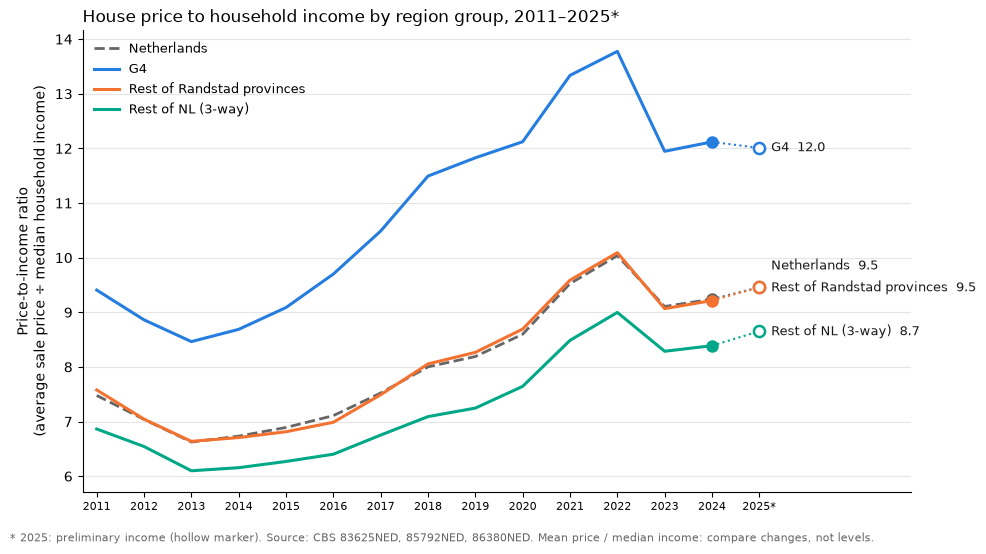

In [5]:
# Colours: categorical slots 1-3 of the reference palette for the three groups (fixed order, validated for
# colour-vision deficiency); NL is a neutral grey reference line. Every line is also labelled directly,
# so identity never depends on colour alone.
STYLE = {
    "Netherlands": dict(color="#666666", lw=2, ls="--"),
    "G4": dict(color="#257de0", lw=2.2),
    "Rest of Randstad provinces": dict(color="#f47230", lw=2.2),
    "Rest of NL (3-way)": dict(color="#00a888", lw=2.2),
}


def spread_labels(values: pd.Series, min_gap: float) -> pd.Series:
    # Push end-of-line label positions apart (bottom-up) so that close lines do not overprint each other.
    pos = values.sort_values().copy()
    for i in range(1, len(pos)):
        pos.iloc[i] = max(pos.iloc[i], pos.iloc[i - 1] + min_gap)
    return pos


fig, ax = plt.subplots(figsize=(10, 5.5))
final_years = [y for y in pti.index if y <= LATEST_FINAL]
label_y = spread_labels(pti.loc[LATEST_DATA, list(STYLE)], min_gap=0.4)
for name, style in STYLE.items():
    s = pti[name]
    ax.plot(final_years, s.loc[final_years], **style, label=name)
    # preliminary year: dotted segment + hollow marker
    ax.plot([LATEST_FINAL, LATEST_DATA], s.loc[[LATEST_FINAL, LATEST_DATA]], color=style["color"], lw=1.5, ls=":")
    ax.plot(LATEST_DATA, s.loc[LATEST_DATA], "o", mfc="white", mec=style["color"], ms=8, mew=1.8)
    ax.plot(LATEST_FINAL, s.loc[LATEST_FINAL], "o", color=style["color"], ms=8)
    ax.annotate(
        f"{name}  {s.loc[LATEST_DATA]:.1f}",
        (LATEST_DATA, s.loc[LATEST_DATA]),
        xytext=(LATEST_DATA + 0.25, label_y[name]),
        textcoords="data",
        va="center",
        fontsize=9,
        color="#191919",
    )

ax.set_xticks(list(pti.index), [YEAR_LABEL[y] for y in pti.index], rotation=0, fontsize=8)
ax.set_xlim(BASE_YEAR - 0.3, LATEST_DATA + 3.2)
ax.set_ylabel("Price-to-income ratio\n(average sale price ÷ median household income)")
ax.set_title(f"House price to household income by region group, {BASE_YEAR}–{YEAR_LABEL[LATEST_DATA]}", loc="left")
ax.grid(axis="y", color="#e5e5e5", lw=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.text(
    0.01,
    0.005,
    f"* {LATEST_DATA}: preliminary income (hollow marker). Source: CBS 83625NED, 85792NED, 86380NED. "
    "Mean price / median income: compare changes, not levels.",
    fontsize=8,
    color="#666666",
)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIG_DIR / "01_pti_by_group.png", dpi=150, facecolor="white")
plt.show()

### 1.2 Robustness checks for section 1

A finding is only a finding if it survives reasonable alternative choices. For this question there are four:

| Check | Why it could change the answer |
|---|---|
| **1A** latest final year vs preliminary year | preliminary incomes are revised; a headline on them can move |
| **1B** owner-occupier income instead of all households | the all-household median is pulled down where many renters and one-person households live (Amsterdam), which inflates the G4 PTI (D-003) |
| **1C** "typical municipality" (median of municipal PTIs) | shows whether the group result is driven by a few large municipalities |
| **1D** real vs nominal | *identity*: cannot change a PTI (see below); shown, never counted as evidence |

#### 1A. Latest final year vs preliminary year

In [6]:
prelim = pd.DataFrame(
    {
        f"PTI {LATEST_FINAL}": pti.loc[LATEST_FINAL],
        f"PTI {YEAR_LABEL[LATEST_DATA]}": pti.loc[LATEST_DATA],
    }
)
prelim["change"] = prelim.iloc[:, 1] - prelim.iloc[:, 0]
prelim["same direction as NL"] = (prelim["change"] > 0) == (prelim.loc["Netherlands", "change"] > 0)
display(prelim)
print(f"Headline numbers in this notebook use {LATEST_FINAL}; {YEAR_LABEL[LATEST_DATA]} is reported as 'preliminary'.")

,PTI 2024,PTI 2025*,change,same direction as NL
group,,,,
Netherlands,9.24,9.46,0.22,True
G4,12.12,12.01,-0.11,False
Rest of Randstad provinces,9.22,9.46,0.24,True
Rest of NL (3-way),8.39,8.65,0.26,True
Rest of NL (2-way: all but G4),8.72,8.97,0.25,True


Headline numbers in this notebook use 2024; 2025* is reported as 'preliminary'.


#### 1B. Owner-occupier income instead of all households

The marts hold the owner-occupier median per municipality (`median_disposable_income_owner_eur`) but no owner-occupier
group income. It is built here **the same way as the main group income** (D-016): the mean of municipal owner-occupier
medians, weighted by the number of owner-occupier households (from the staging income table). Before it is used, it is
validated the same way: over all municipalities it must reproduce the published NL owner-occupier median within 2 %.
The group *prices* are unchanged (same homes, different buyer income).

In [7]:
owner_hh = q("""
    select region_code as municipality_code, year, households_count as owner_households
    from staging.stg_cbs__household_income
    where region_type = 'GM' and household_group = 'owner_occupier'
""")
nl_owner = q("""
    select year, median_disposable_income_eur as nl_owner_median_published
    from staging.stg_cbs__household_income
    where region_type = 'NL' and household_group = 'owner_occupier'
""")

own = (
    fct[["municipality_code", "year", "median_disposable_income_owner_eur"]]
    .merge(owner_hh, on=["municipality_code", "year"], how="left", validate="one_to_one")
    .merge(
        dim_mun[["municipality_code", "region_group", "region_group_3"]], on="municipality_code", validate="many_to_one"
    )
    .dropna(subset=["median_disposable_income_owner_eur", "owner_households"])
)
assert len(own) == fct["median_disposable_income_owner_eur"].notna().sum(), "owner households missing for some rows"


def weighted_owner_income(df: pd.DataFrame) -> pd.Series:
    # Owner-household-weighted mean of municipal owner-occupier medians, per year.
    w = df["median_disposable_income_owner_eur"] * df["owner_households"]
    return w.groupby(df["year"]).sum() / df["owner_households"].groupby(df["year"]).sum()


validation = nl_owner.set_index("year").assign(weighted_mean_of_medians=weighted_owner_income(own))
validation["gap %"] = (validation["weighted_mean_of_medians"] / validation["nl_owner_median_published"] - 1) * 100
print(
    f"Owner-income approximation vs published NL median: gap {validation['gap %'].min():+.2f} % ... "
    f"{validation['gap %'].max():+.2f} % (limit 2 %)"
)
assert validation["gap %"].abs().max() < 2, "owner-occupier approximation outside the D-016 tolerance"

Owner-income approximation vs published NL median: gap +0.38 % ... +0.65 % (limit 2 %)


In [8]:
owner_income = pd.DataFrame(
    {
        "Netherlands": nl_owner.set_index("year")["nl_owner_median_published"],  # published, like the main NL figure
        "G4": weighted_owner_income(own[own["region_group_3"] == "G4"]),
        "Rest of Randstad provinces": weighted_owner_income(own[own["region_group_3"] == "Rest of Randstad provinces"]),
        "Rest of NL (3-way)": weighted_owner_income(own[own["region_group_3"] == "Rest of NL"]),
        "Rest of NL (2-way: all but G4)": weighted_owner_income(own[own["region_group"] == "Rest of NL"]),
    }
).loc[pti.index]

group_price = pd.concat(
    [
        grp.loc[(grp["group_type"] == gt) & (grp["group_code"] == gc), ["year", "avg_sale_price_eur"]].assign(
            group=name
        )
        for gt, gc, name in GROUPS
    ]
).pivot(index="year", columns="group", values="avg_sale_price_eur")[pti.columns]

pti_owner = group_price / owner_income

compare_1b = pd.DataFrame(
    {
        f"all hh: change {BASE_YEAR}-{LATEST_FINAL} %": (pti.loc[LATEST_FINAL] / pti.loc[BASE_YEAR] - 1) * 100,
        f"owner: change {BASE_YEAR}-{LATEST_FINAL} %": (pti_owner.loc[LATEST_FINAL] / pti_owner.loc[BASE_YEAR] - 1)
        * 100,
        f"all hh: PTI {LATEST_FINAL}": pti.loc[LATEST_FINAL],
        f"owner: PTI {LATEST_FINAL}": pti_owner.loc[LATEST_FINAL],
    }
)
display(compare_1b)

gap_all = pti["G4"] / pti["Rest of NL (2-way: all but G4)"]
gap_owner = pti_owner["G4"] / pti_owner["Rest of NL (2-way: all but G4)"]
display(
    pd.DataFrame({"all households": gap_all, "owner-occupiers": gap_owner})
    .loc[[BASE_YEAR, LATEST_FINAL, LATEST_DATA]]
    .rename(index=YEAR_LABEL)
    .rename_axis("G4 / Rest of NL (2-way)")
)

,all hh: change 2011-2024 %,owner: change 2011-2024 %,all hh: PTI 2024,owner: PTI 2024
group,,,,
Netherlands,23.57,17.88,9.24,6.80
G4,28.83,22.81,12.12,7.36
Rest of Randstad provinces,21.59,17.07,9.22,6.96
Rest of NL (3-way),22.21,16.38,8.39,6.39
Rest of NL (2-way: all but G4),21.74,16.37,8.72,6.62


,all households,owner-occupiers
G4 / Rest of NL (2-way),,
2011,1.31,1.05
2024,1.39,1.11
2025*,1.34,1.08


#### 1C. The "typical municipality": median of municipal PTIs per group

Each municipality counts once, whatever its size. Small municipalities are included (D-009: they are excluded only
from rankings). If this view and the group PTI tell the same story, the result is not driven by a few large places.

In [9]:
typical = (
    fct.merge(dim_mun[["municipality_code", "region_group_3"]], on="municipality_code", validate="many_to_one")
    .groupby(["year", "region_group_3"])["price_to_income_ratio"]
    .median()
    .unstack()[["G4", "Rest of Randstad provinces", "Rest of NL"]]
)
typical["all municipalities"] = fct.groupby("year")["price_to_income_ratio"].median()
display(change_table(typical))

,2011,peak,peak year,2024,2025*,change 2011-2024,change 2011-2024 %
region_group_3,,,,,,,
G4,8.50,12.15,2022,10.69,10.79,2.19,25.74
Rest of Randstad provinces,7.09,9.61,2022,8.82,9.05,1.73,24.40
Rest of NL,6.79,8.81,2022,8.12,8.46,1.32,19.50
all municipalities,6.92,9.04,2022,8.37,8.71,1.45,20.90


#### 1D. Real vs nominal

Deflating both price and income by the same CPI leaves the ratio unchanged: (P / CPI) / (Y / CPI) = P / Y. The cell
below proves it on the data, so this check does not need its own table. Real values matter for **growth rates**
("prices rose X % above inflation"), which is section 3.

In [10]:
real_pti = fct["real_avg_sale_price_eur_2025"] / fct["real_median_disposable_income_eur_2025"]
print(
    f"Max |real PTI - nominal PTI| over {real_pti.notna().sum():,} rows: "
    f"{(real_pti - fct['price_to_income_ratio']).abs().max():.1e}"
)

Max |real PTI - nominal PTI| over 5,127 rows: 3.6e-15


#### Robustness register for section 1

Each claim of finding 1 is re-measured under every check. The verdict rule (also used in sections 2–3, D-036):
**holds** = same direction and at least half the size; **weaker** = same direction, less than half the size;
**reverses** = opposite direction. Threshold-type claims (shares, counts) state their own level. The rule is an
editorial heuristic; section 4 shows which labels change under a lenient (¼) and a strict (¾) variant.
Each check also has a **type**: alternative specification, data vintage, data-quality control, or *identity*
(a re-expression that cannot disagree with the baseline: shown, never counted).

In [11]:
REST2 = "Rest of NL (2-way: all but G4)"

# Typical-municipality version of the G4 / Rest of NL ratio (two-way split).
typical2 = (
    fct.merge(dim_mun[["municipality_code", "region_group"]], on="municipality_code", validate="many_to_one")
    .groupby(["year", "region_group"])["price_to_income_ratio"]
    .median()
    .unstack()
)
typical_gap = typical2["G4"] / typical2["Rest of NL"]

nl_rise = pti.loc[LATEST_FINAL, "Netherlands"] - pti.loc[BASE_YEAR, "Netherlands"]
CLAIM_1A = "NL PTI rose since the base year (PTI points)"
record(
    "F1",
    CLAIM_1A,
    "1A preliminary year",
    nl_rise,
    pti.loc[LATEST_DATA, "Netherlands"] - pti.loc[BASE_YEAR, "Netherlands"],
)
record(
    "F1",
    CLAIM_1A,
    "1B owner-occupier income",
    nl_rise,
    pti_owner.loc[LATEST_FINAL, "Netherlands"] - pti_owner.loc[BASE_YEAR, "Netherlands"],
)
record(
    "F1",
    CLAIM_1A,
    "1C typical municipality",
    nl_rise,
    typical.loc[LATEST_FINAL, "all municipalities"] - typical.loc[BASE_YEAR, "all municipalities"],
)

widening = gap_all[LATEST_FINAL] - gap_all[BASE_YEAR]
CLAIM_1B = "G4 / Rest of NL ratio widened since the base year"
record("F1", CLAIM_1B, "1A preliminary year", widening, gap_all[LATEST_DATA] - gap_all[BASE_YEAR])
record("F1", CLAIM_1B, "1B owner-occupier income", widening, gap_owner[LATEST_FINAL] - gap_owner[BASE_YEAR])
record("F1", CLAIM_1B, "1C typical municipality", widening, typical_gap[LATEST_FINAL] - typical_gap[BASE_YEAR])

premium = gap_all[LATEST_FINAL] - 1
CLAIM_1C = "G4 PTI is well above the rest (G4 / Rest of NL - 1)"
record("F1", CLAIM_1C, "1A preliminary year", premium, gap_all[LATEST_DATA] - 1)
record("F1", CLAIM_1C, "1B owner-occupier income", premium, gap_owner[LATEST_FINAL] - 1)
record("F1", CLAIM_1C, "1C typical municipality", premium, typical_gap[LATEST_FINAL] - 1)

for claim, value in [(CLAIM_1A, nl_rise), (CLAIM_1B, widening), (CLAIM_1C, premium)]:
    record("F1", claim, "1D real terms", value, value, kind="identity")  # CPI cancels out of every ratio

display(register("F1").drop(columns="finding"))

,claim,check,type,baseline,variant,verdict
0,NL PTI rose since the base year (PTI points),1A preliminary year,data vintage,+1.76,+1.98,holds
1,NL PTI rose since the base year (PTI points),1B owner-occupier income,alternative specification,+1.76,+1.03,holds
2,NL PTI rose since the base year (PTI points),1C typical municipality,alternative specification,+1.76,+1.45,holds
3,G4 / Rest of NL ratio widened since the base year,1A preliminary year,data vintage,+0.08,+0.03,weaker
4,G4 / Rest of NL ratio widened since the base year,1B owner-occupier income,alternative specification,+0.08,+0.06,holds
5,G4 / Rest of NL ratio widened since the base year,1C typical municipality,alternative specification,+0.08,+0.05,holds
6,G4 PTI is well above the rest (G4 / Rest of NL...,1A preliminary year,data vintage,+0.39,+0.34,holds
7,G4 PTI is well above the rest (G4 / Rest of NL...,1B owner-occupier income,alternative specification,+0.39,+0.11,weaker
8,G4 PTI is well above the rest (G4 / Rest of NL...,1C typical municipality,alternative specification,+0.39,+0.28,holds
9,NL PTI rose since the base year (PTI points),1D real terms,identity,+1.76,+1.76,identical


### Finding 1

In [12]:
gap_peak_year = int(gap_all.idxmax())
nl_peak_year = int(pti["Netherlands"].idxmax())
rest_randstad_vs_nl = pti.loc[LATEST_FINAL, "Rest of Randstad provinces"] / pti.loc[LATEST_FINAL, "Netherlands"]
change_pct = pti_summary[f"change {BASE_YEAR}-{LATEST_FINAL} %"]

# Guards for the wording below.
assert nl_rise > 0, "'rose'"
assert change_pct.idxmax() == "G4", "'the G4 rose most'"
assert widening > 0, "'went from ... to ...' is described as a widening"
assert gap_peak_year < LATEST_FINAL, "'peaked in ... and has narrowed since'"
assert gap_all[LATEST_DATA] < gap_all[LATEST_FINAL], "'the preliminary figure continues that narrowing'"
assert abs(rest_randstad_vs_nl - 1) < 0.02, "'track the national average'"
assert gap_owner[LATEST_FINAL] > gap_owner[BASE_YEAR], "'the widening holds for owner-occupiers'"
assert gap_owner[LATEST_FINAL] - 1 < 0.5 * premium, "'most of the level gap'"
rise_checks = [r for r in ROBUSTNESS if r["claim"] == CLAIM_1A and r["check_type"] in EVIDENCE_TYPES]
smallest_rise = min(rise_checks, key=lambda r: r["variant"])
assert all(r["variant"] > 0 for r in rise_checks), "'the national rise appears under every check'"
assert 0 < gap_all[LATEST_DATA] - gap_all[BASE_YEAR] < widening, "'the preliminary year weakens the widening'"

display(
    Markdown(f"""
**Finding 1. Homes became less affordable everywhere, most of all in the G4, but the G4's lead peaked in
{gap_peak_year} and is to a large extent a household-mix effect.**

Between {BASE_YEAR} and {LATEST_FINAL} the national PTI rose from {pti.loc[BASE_YEAR, "Netherlands"]:.1f} to
{pti.loc[LATEST_FINAL, "Netherlands"]:.1f} (+{change_pct["Netherlands"]:.0f} %), after a peak of
{pti.loc[nl_peak_year, "Netherlands"]:.1f} in {nl_peak_year}. The G4 rose most
({pti.loc[BASE_YEAR, "G4"]:.1f} → {pti.loc[LATEST_FINAL, "G4"]:.1f}, +{change_pct["G4"]:.0f} %), so its PTI relative to
the rest of NL went from {gap_all[BASE_YEAR]:.2f}× to {gap_all[LATEST_FINAL]:.2f}×. That lead peaked at
{gap_all[gap_peak_year]:.2f}× in {gap_peak_year} and has narrowed since; the preliminary {YEAR_LABEL[LATEST_DATA]} figure
({gap_all[LATEST_DATA]:.2f}×) continues the narrowing. The other municipalities of the three Randstad provinces track the
national average ({pti.loc[LATEST_FINAL, "Rest of Randstad provinces"]:.2f} vs {pti.loc[LATEST_FINAL, "Netherlands"]:.2f}):
at group level the premium sits in the four cities, not in the region around them.

**Robustness.** The national rise appears under every check (smallest: {smallest_rise["variant"]:+.2f} PTI points,
{smallest_rise["check"][3:]}). With owner-occupier income the G4's lead still widens
({gap_owner[BASE_YEAR]:.2f}× → {gap_owner[LATEST_FINAL]:.2f}×), but its size shrinks from {gap_all[LATEST_FINAL]:.2f}×
to {gap_owner[LATEST_FINAL]:.2f}×: most of the G4's level gap comes from *who lives there* (many renters and one-person
households with lower incomes), not only from what homes cost. The preliminary year weakens the widening, because the
narrowing since {gap_peak_year} continues.

**So what.** "The G4 is unaffordable" needs a qualifier. Relative to the incomes of the people who already own there,
G4 homes are only slightly dearer than elsewhere; the barrier is for lower-income, mostly renting households who want to
buy. For lenders and policy makers this means targeting first-time buyers on G4 incomes, not "the G4" as a whole.
""")
)


**Finding 1. Homes became less affordable everywhere, most of all in the G4, but the G4's lead peaked in
2019 and is to a large extent a household-mix effect.**

Between 2011 and 2024 the national PTI rose from 7.5 to
9.2 (+24 %), after a peak of
10.0 in 2022. The G4 rose most
(9.4 → 12.1, +29 %), so its PTI relative to
the rest of NL went from 1.31× to 1.39×. That lead peaked at
1.55× in 2019 and has narrowed since; the preliminary 2025* figure
(1.34×) continues the narrowing. The other municipalities of the three Randstad provinces track the
national average (9.22 vs 9.24):
at group level the premium sits in the four cities, not in the region around them.

**Robustness.** The national rise appears under every check (smallest: +1.03 PTI points,
owner-occupier income). With owner-occupier income the G4's lead still widens
(1.05× → 1.11×), but its size shrinks from 1.39×
to 1.11×: most of the G4's level gap comes from *who lives there* (many renters and one-person
households with lower incomes), not only from what homes cost. The preliminary year weakens the widening, because the
narrowing since 2019 continues.

**So what.** "The G4 is unaffordable" needs a qualifier. Relative to the incomes of the people who already own there,
G4 homes are only slightly dearer than elsewhere; the barrier is for lower-income, mostly renting households who want to
buy. For lenders and policy makers this means targeting first-time buyers on G4 incomes, not "the G4" as a whole.


---
## 2. Which municipalities are the least / most affordable, and how did the ranking change?

**Ranking rules (D-009).** Rank 1 = highest PTI = least affordable. Municipalities with fewer than 5 000 households
(`low_reliability`) or without income (`income_missing`) get no rank: their averages rest on a handful of sales.

**Why a fixed panel for rank changes.** The set of ranked municipalities changes over time (a municipality can grow past
5 000 households, as Laren and Blaricum did). A rank out of 316 and a rank out of 323 are not comparable, so rank
*changes* are computed on the **panel** of municipalities that are ranked in both years, re-ranked within that panel.

In [13]:
mun = fct.merge(
    dim_mun[["municipality_code", "municipality_name", "province_name", "region_group", "region_group_3", "is_g4"]],
    on="municipality_code",
    validate="many_to_one",
)
G4_CODES = dim_mun.loc[dim_mun["is_g4"], "municipality_code"].tolist()
GROUP_OF = dim_mun.set_index("municipality_code")["region_group_3"]
NAME_OF = dim_mun.set_index("municipality_code")["municipality_name"]


def ranks(year: int, col: str = "price_to_income_ratio", include_small: bool = False, among=None) -> pd.Series:
    # Rank 1 = least affordable, over the D-009 ranked set of `year` (optionally with small municipalities,
    # optionally restricted to the codes in `among`). Index = municipality_code.
    d = mun[mun["year"] == year].set_index("municipality_code")
    keep = d[col].notna() & ~d["income_missing"]
    if not include_small:
        keep &= ~d["low_reliability"]
    if among is not None:
        keep &= d.index.isin(among)
    return d.loc[keep, col].rank(ascending=False, method="min").astype(int)


def spearman(a: pd.Series, b: pd.Series) -> float:
    # Spearman rank correlation = Pearson correlation of the ranks (no scipy needed). Aligned on the index.
    a, b = a.align(b, join="inner")
    return float(a.rank().corr(b.rank()))


def top(r: pd.Series, n: int) -> pd.Index:
    # Codes of the n least affordable municipalities in a rank series.
    return r.sort_values(kind="stable").head(n).index


# The helper must reproduce the rank stored in the mart.
stored = fct.loc[fct["year"] == LATEST_FINAL].set_index("municipality_code")["pti_rank_desc"].dropna().astype(int)
assert ranks(LATEST_FINAL).sort_index().equals(stored.sort_index()), "ranks() differs from pti_rank_desc"

r_final = ranks(LATEST_FINAL)
panel = ranks(BASE_YEAR).index.intersection(r_final.index)
pr_base, pr_final = ranks(BASE_YEAR, among=panel), ranks(LATEST_FINAL, among=panel)
print(
    f"Ranked in {LATEST_FINAL}: {len(r_final)} | ranked in {BASE_YEAR}: {len(ranks(BASE_YEAR))} | "
    f"panel (ranked in both): {len(panel)}"
)

Ranked in 2024: 323 | ranked in 2011: 316 | panel (ranked in both): 316


### 2.1 Result: least and most affordable municipalities

In [14]:
head = mun[mun["year"] == LATEST_FINAL].set_index("municipality_code")
base = mun[mun["year"] == BASE_YEAR].set_index("municipality_code")

ranking = pd.DataFrame(
    {
        "municipality": head["municipality_name"],
        "province": head["province_name"],
        "group": head["region_group_3"],
        f"PTI {BASE_YEAR}": base["price_to_income_ratio"],
        f"PTI {LATEST_FINAL}": head["price_to_income_ratio"],
        f"rank {LATEST_FINAL}": r_final,
        f"panel rank {BASE_YEAR}": pr_base,
        f"panel rank {LATEST_FINAL}": pr_final,
    }
).loc[r_final.index]
# positive = moved towards the least affordable end of the ranking
ranking["panel rank change"] = ranking[f"panel rank {BASE_YEAR}"] - ranking[f"panel rank {LATEST_FINAL}"]
rank_cols = [f"rank {LATEST_FINAL}", f"panel rank {BASE_YEAR}", f"panel rank {LATEST_FINAL}", "panel rank change"]
ranking = ranking.astype(dict.fromkeys(rank_cols, "Int64")).sort_values(f"rank {LATEST_FINAL}")

display(
    Markdown(
        f"**Least affordable, {LATEST_FINAL}** (rank 1 = highest PTI, {len(ranking)} ranked municipalities; "
        f"an empty panel rank = not ranked in {BASE_YEAR})"
    )
)
display(ranking.head(10))
display(Markdown(f"**Most affordable, {LATEST_FINAL}**"))
display(ranking.tail(10))

**Least affordable, 2024** (rank 1 = highest PTI, 323 ranked municipalities; an empty panel rank = not ranked in 2011)

,municipality,province,group,PTI 2011,PTI 2024,rank 2024,panel rank 2011,panel rank 2024,panel rank change
municipality_code,,,,,,,,,
GM0417,Laren (NH),Noord-Holland,Rest of Randstad provinces,14.63,17.29,1,<NA>,<NA>,<NA>
GM0376,Blaricum,Noord-Holland,Rest of Randstad provinces,19.00,15.73,2,<NA>,<NA>,<NA>
GM0377,Bloemendaal,Noord-Holland,Rest of Randstad provinces,15.31,15.19,3,1,1,0
GM0629,Wassenaar,Zuid-Holland,Rest of Randstad provinces,15.00,14.91,4,2,2,0
GM0363,Amsterdam,Noord-Holland,G4,11.06,14.71,5,8,3,5
GM0373,Bergen (NH),Noord-Holland,Rest of Randstad provinces,12.13,13.34,6,5,4,1
GM0473,Zandvoort,Noord-Holland,Rest of Randstad provinces,10.41,12.99,7,11,5,6
GM0310,De Bilt,Utrecht,Rest of Randstad provinces,12.52,12.48,8,4,6,-2
GM0362,Amstelveen,Noord-Holland,Rest of Randstad provinces,9.26,12.45,9,17,7,10


**Most affordable, 2024**

,municipality,province,group,PTI 2011,PTI 2024,rank 2024,panel rank 2011,panel rank 2024,panel rank change
municipality_code,,,,,,,,,
GM0889,Beesel,Limburg,Rest of NL,6.43,6.57,314,218,307,-89
GM0882,Landgraaf,Limburg,Rest of NL,5.55,6.56,315,297,308,-11
GM0531,Hendrik-Ido-Ambacht,Zuid-Holland,Rest of Randstad provinces,6.04,6.44,316,263,309,-46
GM0899,Brunssum,Limburg,Rest of NL,5.21,6.43,317,309,310,-1
GM0677,Hulst,Zeeland,Rest of NL,5.39,6.40,318,303,311,-8
GM0047,Veendam,Groningen,Rest of NL,5.15,6.34,319,311,312,-1
GM0716,Tholen,Zeeland,Rest of NL,5.80,6.32,320,284,313,-29
GM0765,Pekela,Groningen,Rest of NL,4.75,6.08,321,315,314,1
GM0715,Terneuzen,Zeeland,Rest of NL,4.83,6.05,322,314,315,-1


In [15]:
TOP_N = 25
comp = (
    pd.DataFrame(
        {
            f"least affordable {TOP_N}": ranking.head(TOP_N)["group"].value_counts(),
            f"most affordable {TOP_N}": ranking.tail(TOP_N)["group"].value_counts(),
            "all ranked": ranking["group"].value_counts(),
        }
    )
    .reindex(["G4", "Rest of Randstad provinces", "Rest of NL"])
    .fillna(0)
    .astype(int)
)
display(comp)
display(ranking.loc[G4_CODES, ["municipality", f"PTI {LATEST_FINAL}", f"rank {LATEST_FINAL}"]])

,least affordable 25,most affordable 25,all ranked
group,,,
G4,2,0,4
Rest of Randstad provinces,22,3,110
Rest of NL,1,22,209


,municipality,PTI 2024,rank 2024
municipality_code,,,
GM0344,Utrecht,10.90,20
GM0363,Amsterdam,14.71,5
GM0518,'s-Gravenhage,10.48,26
GM0599,Rotterdam,9.92,40


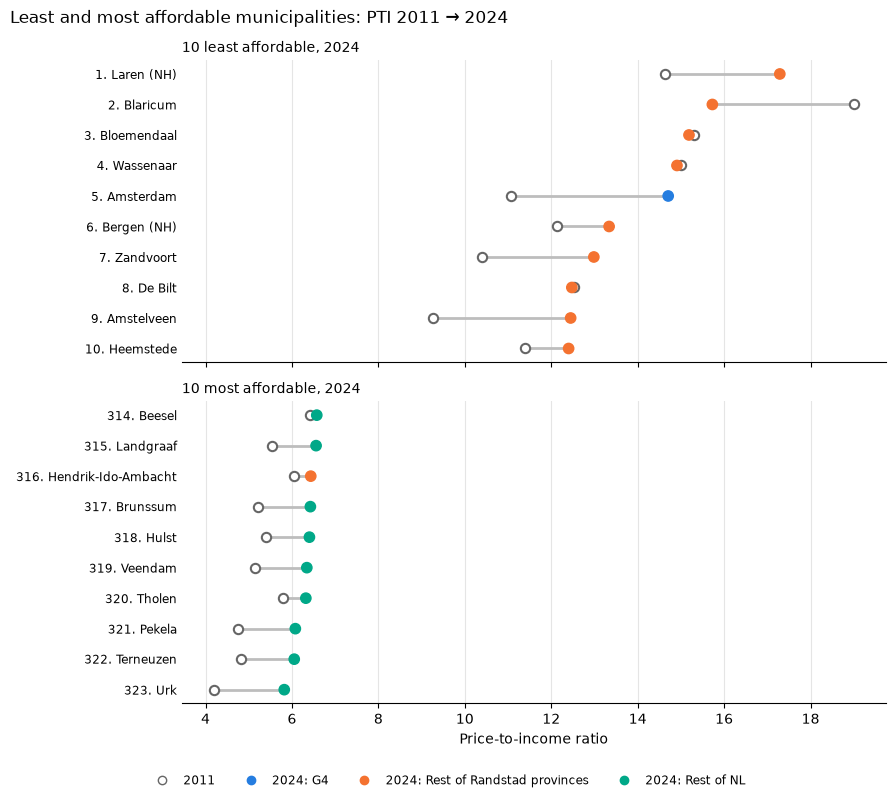

In [16]:
GROUP_COLOR = {"G4": "#257de0", "Rest of Randstad provinces": "#f47230", "Rest of NL": "#00a888"}


def dumbbell(ax, rows: pd.DataFrame, title: str) -> None:
    # Base-year PTI (hollow) -> headline-year PTI (filled, group colour), one row per municipality.
    rows = rows.iloc[::-1]  # rank 1 at the top
    y = np.arange(len(rows))
    ax.hlines(y, rows[f"PTI {BASE_YEAR}"], rows[f"PTI {LATEST_FINAL}"], color="#bdbdbd", lw=2)
    ax.scatter(rows[f"PTI {BASE_YEAR}"], y, s=45, facecolor="white", edgecolor="#666666", lw=1.5, zorder=3)
    ax.scatter(rows[f"PTI {LATEST_FINAL}"], y, s=55, color=rows["group"].map(GROUP_COLOR), zorder=3)
    ax.set_yticks(
        y, [f"{r}. {m}" for r, m in zip(rows[f"rank {LATEST_FINAL}"], rows["municipality"], strict=True)], fontsize=8.5
    )
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(axis="x", color="#e5e5e5", lw=0.8)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
dumbbell(ax1, ranking.head(10), f"10 least affordable, {LATEST_FINAL}")
dumbbell(ax2, ranking.tail(10), f"10 most affordable, {LATEST_FINAL}")
ax2.set_xlabel("Price-to-income ratio")
handles = [plt.Line2D([], [], marker="o", ls="", mfc="white", mec="#666666", label=f"{BASE_YEAR}")] + [
    plt.Line2D([], [], marker="o", ls="", color=c, label=f"{LATEST_FINAL}: {g}") for g, c in GROUP_COLOR.items()
]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, fontsize=8.5)
fig.suptitle(f"Least and most affordable municipalities: PTI {BASE_YEAR} → {LATEST_FINAL}", x=0.01, ha="left")
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG_DIR / "02_least_most_affordable.png", dpi=150, facecolor="white")
plt.show()

### 2.2 How persistent is the ranking?

Spearman's rank correlation between the base year and the headline year on the panel: 1 = identical order,
0 = no relation. Large individual moves are listed with `is_harmonised`: a municipality that was merged later has a
base-year price that is a weighted average of its predecessors (D-007), so its early rank is less precise.

In [17]:
rho = spearman(pr_base, pr_final)
print(f"Spearman rank correlation {BASE_YEAR} vs {LATEST_FINAL} (panel of {len(panel)}): {rho:.2f}")

movers = ranking.dropna(subset=["panel rank change"]).copy()
movers[f"harmonised in {BASE_YEAR}"] = base.loc[movers.index, "is_harmonised"]
cols = [
    "municipality",
    "group",
    f"PTI {BASE_YEAR}",
    f"PTI {LATEST_FINAL}",
    f"panel rank {BASE_YEAR}",
    f"panel rank {LATEST_FINAL}",
    "panel rank change",
    f"harmonised in {BASE_YEAR}",
]
display(Markdown("**Largest moves towards *less* affordable**"))
display(movers.nlargest(5, "panel rank change")[cols])
display(Markdown("**Largest moves towards *more* affordable**"))
display(movers.nsmallest(5, "panel rank change")[cols])

Spearman rank correlation 2011 vs 2024 (panel of 316): 0.85


**Largest moves towards *less* affordable**

,municipality,group,PTI 2011,PTI 2024,panel rank 2011,panel rank 2024,panel rank change,harmonised in 2011
municipality_code,,,,,,,,
GM1773,Olst-Wijhe,Rest of NL,5.46,8.50,301,145,156,False
GM0995,Lelystad,Rest of NL,5.58,8.37,296,155,141,False
GM0034,Almere,Rest of NL,5.98,8.57,267,135,132,False
GM0388,Enkhuizen,Rest of Randstad provinces,6.12,8.58,258,132,126,False
GM0637,Zoetermeer,Rest of Randstad provinces,5.96,8.44,269,148,121,False


**Largest moves towards *more* affordable**

,municipality,group,PTI 2011,PTI 2024,panel rank 2011,panel rank 2024,panel rank change,harmonised in 2011
municipality_code,,,,,,,,
GM0331,Lopik,Rest of Randstad provinces,7.75,7.98,68,200,-132,False
GM0762,Deurne,Rest of NL,7.95,8.19,56,174,-118,False
GM0168,Losser,Rest of NL,7.03,7.50,139,253,-114,False
GM0213,Brummen,Rest of NL,7.35,7.87,104,215,-111,False
GM0225,Druten,Rest of NL,7.49,8.01,88,198,-110,False


### 2.3 Robustness checks for section 2

| Check | Why it could change the answer |
|---|---|
| **2A** owner-occupier PTI ranks | ranks by all-household income partly reflect how many renters live in a municipality |
| **2B** small municipalities included | D-009 removes them; does that change the picture? |
| **2C** preliminary year | is the headline ranking stable one year later? |
| **2D** harmonised municipalities removed | early prices of later-merged municipalities are reconstructed (D-007) |

#### 2A. Owner-occupier PTI ranks

In [18]:
r_owner = ranks(LATEST_FINAL, col="price_to_income_owner_ratio")
assert r_owner.index.sort_values().equals(r_final.index.sort_values()), "owner ranks use a different set"
rho_all_vs_owner = spearman(r_final, r_owner)
rho_owner_panel = spearman(
    ranks(BASE_YEAR, "price_to_income_owner_ratio", among=panel),
    ranks(LATEST_FINAL, "price_to_income_owner_ratio", among=panel),
)
print(f"Rank correlation all-household vs owner-occupier PTI, {LATEST_FINAL}: {rho_all_vs_owner:.2f}")
print(f"Owner-occupier ranks, {BASE_YEAR} vs {LATEST_FINAL} (panel): {rho_owner_panel:.2f}")
print(f"Top-10 overlap: {len(top(r_final, 10).intersection(top(r_owner, 10)))} of 10")

third = len(r_final) / 3
g4_ranks = pd.DataFrame(
    {
        "municipality": NAME_OF[G4_CODES],
        "rank (all households)": r_final[G4_CODES],
        "rank (owner-occupiers)": r_owner[G4_CODES],
    }
)
display(g4_ranks)
print(f"Least-affordable third = rank <= {third:.0f}")

Rank correlation all-household vs owner-occupier PTI, 2024: 0.86
Owner-occupier ranks, 2011 vs 2024 (panel): 0.85
Top-10 overlap: 8 of 10


,municipality,rank (all households),rank (owner-occupiers)
municipality_code,,,
GM0344,Utrecht,20,148
GM0363,Amsterdam,5,14
GM0518,'s-Gravenhage,26,131
GM0599,Rotterdam,40,234


Least-affordable third = rank <= 108


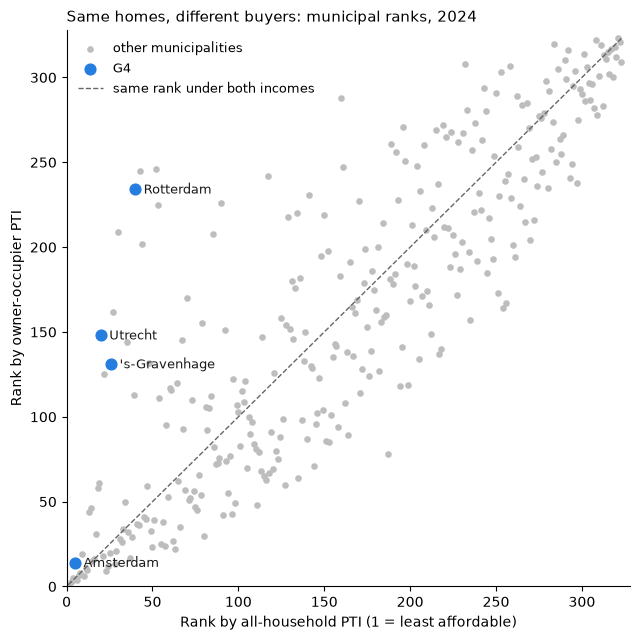

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))
others = r_final.index.difference(G4_CODES)
ax.scatter(r_final[others], r_owner[others], s=14, color="#bdbdbd", label="other municipalities")
ax.scatter(r_final[G4_CODES], r_owner[G4_CODES], s=60, color=GROUP_COLOR["G4"], label="G4", zorder=3)
for code_ in G4_CODES:
    ax.annotate(
        NAME_OF[code_],
        (r_final[code_], r_owner[code_]),
        xytext=(6, -3),
        textcoords="offset points",
        fontsize=9,
        color="#191919",
    )
n = len(r_final)
ax.plot([1, n], [1, n], color="#666666", lw=1, ls="--", label="same rank under both incomes")
ax.set(
    xlim=(0, n + 5),
    ylim=(0, n + 5),
    xlabel="Rank by all-household PTI (1 = least affordable)",
    ylabel="Rank by owner-occupier PTI",
)
ax.set_title(f"Same homes, different buyers: municipal ranks, {LATEST_FINAL}", loc="left", fontsize=11)
ax.legend(frameon=False, loc="upper left", fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_rank_all_vs_owner.png", dpi=150, facecolor="white")
plt.show()

#### 2B. Small municipalities included

In [20]:
r_small = ranks(LATEST_FINAL, include_small=True)
entered = top(r_small, 10).difference(top(r_final, 10))
print(f"Ranked with small municipalities: {len(r_small)} (+{len(r_small) - len(r_final)})")
print(f"New in the top 10: {', '.join(NAME_OF[entered])}")
panel_small = ranks(BASE_YEAR, include_small=True).index.intersection(r_small.index)
rho_small = spearman(
    ranks(BASE_YEAR, include_small=True, among=panel_small),
    ranks(LATEST_FINAL, include_small=True, among=panel_small),
)
print(f"Rank correlation {BASE_YEAR} vs {LATEST_FINAL} incl. small (panel of {len(panel_small)}): {rho_small:.2f}")

Ranked with small municipalities: 342 (+19)
New in the top 10: Vlieland
Rank correlation 2011 vs 2024 incl. small (panel of 342): 0.85


#### 2C. Preliminary year

In [21]:
r_prelim = ranks(LATEST_DATA)
panel_prelim = ranks(BASE_YEAR).index.intersection(r_prelim.index)
rho_prelim = spearman(ranks(BASE_YEAR, among=panel_prelim), ranks(LATEST_DATA, among=panel_prelim))
print(
    f"Top-10 overlap {LATEST_FINAL} vs {YEAR_LABEL[LATEST_DATA]}: "
    f"{len(top(r_final, 10).intersection(top(r_prelim, 10)))} of 10"
)
print(f"Rank correlation {BASE_YEAR} vs {YEAR_LABEL[LATEST_DATA]} (panel of {len(panel_prelim)}): {rho_prelim:.2f}")

Top-10 overlap 2024 vs 2025*: 10 of 10
Rank correlation 2011 vs 2025* (panel of 316): 0.84


#### 2D. Harmonised municipalities removed

In [22]:
harmonised_ever = fct.groupby("municipality_code")["is_harmonised"].any()
panel_clean = panel[~harmonised_ever.loc[panel].to_numpy()]
rho_clean = spearman(ranks(BASE_YEAR, among=panel_clean), ranks(LATEST_FINAL, among=panel_clean))
print(
    f"Panel without municipalities harmonised in any year: {len(panel_clean)} of {len(panel)}; "
    f"rank correlation {rho_clean:.2f}"
)

Panel without municipalities harmonised in any year: 272 of 316; rank correlation 0.84


In [23]:
def share_rest_randstad(codes: pd.Index) -> float:
    # Share of the given municipalities that lie in the Randstad provinces outside the G4.
    return float((GROUP_OF[codes] == "Rest of Randstad provinces").mean())


def g4_in_top_third(r: pd.Series) -> int:
    # Number of G4 cities in the least-affordable third of a ranking.
    return int((r.reindex(G4_CODES) <= len(r) / 3).sum())


# Levels each threshold-type claim must reach: (holds at, weaker at) per rule set (D-036).
MAJORITY = {"lenient": (0.4, None), "default": (0.5, None), "strict": (0.6, None)}
PERSISTENT = {"lenient": (0.6, 0.4), "default": (0.7, 0.5), "strict": (0.8, 0.6)}
G4_COUNT = {"lenient": (2, 1), "default": (3, 2), "strict": (4, 3)}


CLAIM_2A = f"Least-affordable {TOP_N} are mostly Randstad suburbs (share; holds if >= 50 %)"
base_share = share_rest_randstad(top(r_final, TOP_N))
for check, r in [
    ("2A owner-occupier PTI", r_owner),
    ("2B small municipalities incl.", r_small),
    ("2C preliminary year", r_prelim),
]:
    x = share_rest_randstad(top(r, TOP_N))
    record("F2", CLAIM_2A, check, base_share, x, fmt="{:.0%}", kind="threshold", thresholds=MAJORITY)

CLAIM_2B = "Ranking is persistent (Spearman base vs headline year; holds if >= 0.7)"
for check, x in [
    ("2A owner-occupier PTI", rho_owner_panel),
    ("2B small municipalities incl.", rho_small),
    ("2C preliminary year", rho_prelim),
    ("2D harmonised removed", rho_clean),
]:
    record("F2", CLAIM_2B, check, rho, x, kind="threshold", thresholds=PERSISTENT)

CLAIM_2C = "G4 cities are in the least-affordable third (count of 4; holds if >= 3)"
base_g4 = g4_in_top_third(r_final)
for check, r in [
    ("2A owner-occupier PTI", r_owner),
    ("2B small municipalities incl.", r_small),
    ("2C preliminary year", r_prelim),
]:
    x = g4_in_top_third(r)
    record("F2", CLAIM_2C, check, base_g4, x, fmt="{:.0f}", kind="threshold", thresholds=G4_COUNT)

display(register("F2").drop(columns="finding"))

,claim,check,type,baseline,variant,verdict
0,Least-affordable 25 are mostly Randstad suburb...,2A owner-occupier PTI,alternative specification,88%,72%,holds
1,Least-affordable 25 are mostly Randstad suburb...,2B small municipalities incl.,alternative specification,88%,84%,holds
2,Least-affordable 25 are mostly Randstad suburb...,2C preliminary year,data vintage,88%,88%,holds
3,Ranking is persistent (Spearman base vs headli...,2A owner-occupier PTI,alternative specification,+0.85,+0.85,holds
4,Ranking is persistent (Spearman base vs headli...,2B small municipalities incl.,alternative specification,+0.85,+0.85,holds
5,Ranking is persistent (Spearman base vs headli...,2C preliminary year,data vintage,+0.85,+0.84,holds
6,Ranking is persistent (Spearman base vs headli...,2D harmonised removed,data-quality control,+0.85,+0.84,holds
7,G4 cities are in the least-affordable third (c...,2A owner-occupier PTI,alternative specification,4,1,reverses
8,G4 cities are in the least-affordable third (c...,2B small municipalities incl.,alternative specification,4,4,holds
9,G4 cities are in the least-affordable third (c...,2C preliminary year,data vintage,4,4,holds


### Finding 2

In [24]:
top3 = top(r_final, 3)
top10 = top(r_final, 10)
g4_in_top10 = [c for c in G4_CODES if c in top10]
bottom10 = r_final.sort_values(kind="stable").tail(10).index
bottom_outside = int((GROUP_OF[bottom10] == "Rest of NL").sum())
bottom_provinces = head.loc[bottom10, "province_name"].value_counts()
k_suburbs = int(round(base_share * TOP_N))
owner_g4_third = g4_in_top_third(r_owner)
rot = dim_mun.loc[dim_mun["municipality_name"] == "Rotterdam", "municipality_code"].item()
WORDS = {1: "one", 2: "two", 3: "three", 4: "all four"}
entered_text = (
    f"{NAME_OF[entered[0]]}, whose average rests"
    if len(entered) == 1
    else f"{', '.join(NAME_OF[entered])}, whose averages rest"
)

most_affordable_randstad = int(comp.loc["Rest of Randstad provinces", f"most affordable {TOP_N}"])

assert base_share >= 0.5, "'mostly'"
assert most_affordable_randstad >= 1, "'the same provinces also hold some of the most affordable'"
assert g4_in_top10 == [dim_mun.loc[dim_mun["municipality_name"] == "Amsterdam", "municipality_code"].item()], (
    "'Amsterdam is the only G4 city in the top 10'"
)
assert bottom_outside >= 8, "'nearly all ... outside the Randstad provinces'"
assert rho >= 0.8, "'the order barely changed'"
assert set(top(r_owner, 3)) == set(top3), "'the top 3 are the same'"
min_share = min(r["variant"] for r in ROBUSTNESS if r["claim"] == CLAIM_2A)
min_rho = min(r["variant"] for r in ROBUSTNESS if r["claim"] == CLAIM_2B)
assert min_share > 0.5 and min_rho >= 0.8, "'the suburban top and the persistence survive every check'"
assert owner_g4_third <= 1, "'three of the four G4 cities drop out'"

display(
    Markdown(f"""
**Finding 2. The least affordable places are the wealthy suburbs around the big cities, not the G4 themselves, and the
ranking hardly moves over time.**

In {LATEST_FINAL}, {k_suburbs} of the {TOP_N} least affordable municipalities lie in the Randstad provinces outside the G4;
the top three are {", ".join(NAME_OF[top3])} (PTI {", ".join(f"{v:.1f}" for v in head.loc[top3, "price_to_income_ratio"])}).
Amsterdam (rank {r_final[g4_in_top10[0]]}) is the only G4 city in the top 10. At the other end, {bottom_outside} of the
10 most affordable municipalities are outside the Randstad provinces, mostly in {", ".join(bottom_provinces.index[:3])}.
The order barely changed in {LATEST_FINAL - BASE_YEAR} years: the rank correlation between {BASE_YEAR} and {LATEST_FINAL}
is {rho:.2f}. This is what the group average of finding 1 hides: the Randstad provinces outside the G4 hold both the
least affordable municipalities and {most_affordable_randstad} of the {TOP_N} most affordable ones.

**Robustness.** The suburban top and the persistence survive every check: the suburbs' share of the top {TOP_N}
stays at {min_share * 100:.0f} % or more and the rank correlation at {min_rho:.2f} or more. Ranked by owner-occupier income the top three
are the same, but {WORDS[4 - owner_g4_third]} of the four G4 cities leave the least-affordable third (Rotterdam: rank
{r_final[rot]} → {r_owner[rot]}): the cities look unaffordable mainly because many of their households are renters with
lower incomes. Including the small municipalities adds {entered_text} on few sales,
to the top 10 (the reason small municipalities are not ranked, D-009).

**So what.** Affordability is a regional problem with a stable geography: today's least affordable places were already
near the top a decade ago, so the gap is structural, not a temporary spike. Policy or products that look only at the four
big cities miss the most expensive places relative to income.
""")
)


**Finding 2. The least affordable places are the wealthy suburbs around the big cities, not the G4 themselves, and the
ranking hardly moves over time.**

In 2024, 22 of the 25 least affordable municipalities lie in the Randstad provinces outside the G4;
the top three are Laren (NH), Blaricum, Bloemendaal (PTI 17.3, 15.7, 15.2).
Amsterdam (rank 5) is the only G4 city in the top 10. At the other end, 9 of the
10 most affordable municipalities are outside the Randstad provinces, mostly in Limburg, Zeeland, Groningen.
The order barely changed in 13 years: the rank correlation between 2011 and 2024
is 0.85. This is what the group average of finding 1 hides: the Randstad provinces outside the G4 hold both the
least affordable municipalities and 3 of the 25 most affordable ones.

**Robustness.** The suburban top and the persistence survive every check: the suburbs' share of the top 25
stays at 72 % or more and the rank correlation at 0.84 or more. Ranked by owner-occupier income the top three
are the same, but three of the four G4 cities leave the least-affordable third (Rotterdam: rank
40 → 234): the cities look unaffordable mainly because many of their households are renters with
lower incomes. Including the small municipalities adds Vlieland, whose average rests on few sales,
to the top 10 (the reason small municipalities are not ranked, D-009).

**So what.** Affordability is a regional problem with a stable geography: today's least affordable places were already
near the top a decade ago, so the gap is structural, not a temporary spike. Policy or products that look only at the four
big cities miss the most expensive places relative to income.


---
## 3. Where did prices grow faster than incomes: the G4 vs the regions?

The PTI changes when price growth and income growth differ: PTI change = (1 + price growth) / (1 + income growth) − 1.
This section splits that into its two parts, in nominal and in real (CPI-deflated, 2025 euro, D-027) terms.

**Nominal vs real.** Deflating both by the same CPI does not change the ratio, but it does change the *difference in
percentage points* (the `growth_gap_pp` column of the marts). The real figures answer the question a reader actually
asks: "did prices and incomes grow faster than inflation?"

### 3.1 Result: price vs income growth by group

In [25]:
def group_series(gt: str, gc: str) -> pd.DataFrame:
    # One group's rows from the group fact, indexed by year.
    return grp[(grp["group_type"] == gt) & (grp["group_code"] == gc)].set_index("year")


def growth_table(start: int, end: int, groups=GROUPS) -> pd.DataFrame:
    # Nominal and real price / income growth between two years, per group.
    rows = {}
    for gt, gc, name in groups:
        g = group_series(gt, gc)
        rows[name] = {
            "price %": pct(g.loc[end, "avg_sale_price_eur"], g.loc[start, "avg_sale_price_eur"]),
            "income %": pct(g.loc[end, "median_disposable_income_eur"], g.loc[start, "median_disposable_income_eur"]),
            "real price %": pct(
                g.loc[end, "real_avg_sale_price_eur_2025"], g.loc[start, "real_avg_sale_price_eur_2025"]
            ),
            "real income %": pct(
                g.loc[end, "real_median_disposable_income_eur_2025"],
                g.loc[start, "real_median_disposable_income_eur_2025"],
            ),
        }
    t = pd.DataFrame(rows).T
    t["gap pp"] = t["price %"] - t["income %"]
    t["real gap pp"] = t["real price %"] - t["real income %"]
    t["PTI change %"] = ((1 + t["price %"] / 100) / (1 + t["income %"] / 100) - 1) * 100
    return t


growth = growth_table(BASE_YEAR, LATEST_FINAL)

# Cross-check against the growth columns of the mart (same definition, computed in SQL).
mart_gap = pd.Series({name: group_series(gt, gc).loc[LATEST_FINAL, "growth_gap_pp"] for gt, gc, name in GROUPS})
assert (growth["gap pp"] - mart_gap).abs().max() < 1e-9, "notebook growth != fct_group_affordability"
assert (growth["PTI change %"] - pti_summary[f"change {BASE_YEAR}-{LATEST_FINAL} %"]).abs().max() < 1e-9

display(Markdown(f"**Growth {BASE_YEAR} → {LATEST_FINAL}**"))
display(growth)

**Growth 2011 → 2024**

,price %,income %,real price %,real income %,gap pp,real gap pp,PTI change %
Netherlands,87.86,52.02,35.13,9.35,35.84,25.78,23.57
G4,108.24,61.64,49.78,16.26,46.60,33.52,28.83
Rest of Randstad provinces,84.26,51.53,32.54,9.00,32.72,23.54,21.59
Rest of NL (3-way),84.58,51.03,32.77,8.64,33.55,24.13,22.21
Rest of NL (2-way: all but G4),84.12,51.24,32.44,8.79,32.88,23.65,21.74


### 3.2 When did the G4 pull ahead, and when did the rest catch up?

The sub-periods are not chosen by eye. Their break points come from the data: the national PTI low before the boom,
the year the G4 / Rest of NL ratio peaked (section 1), and the national PTI peak.

In [26]:
nl_pti = pti["Netherlands"]
trough_year = int(nl_pti.loc[:nl_peak_year].idxmin())
breaks = sorted({BASE_YEAR, trough_year, gap_peak_year, nl_peak_year, LATEST_FINAL})
periods = list(zip(breaks[:-1], breaks[1:], strict=True))
TWO_WAY = [GROUPS[1], GROUPS[4]]  # G4, Rest of NL (2-way)

sub = pd.DataFrame(
    {
        f"{a}-{b}": {
            "G4 price %": t.loc["G4", "price %"],
            "Rest of NL price %": t.loc[REST2, "price %"],
            "G4 minus rest, price pp": t.loc["G4", "price %"] - t.loc[REST2, "price %"],
            "G4 income %": t.loc["G4", "income %"],
            "Rest of NL income %": t.loc[REST2, "income %"],
        }
        for a, b in periods
        for t in [growth_table(a, b, TWO_WAY)]
    }
).T
print(f"Break points: NL trough {trough_year}, G4-lead peak {gap_peak_year}, NL peak {nl_peak_year}")
display(sub)

Break points: NL trough 2013, G4-lead peak 2019, NL peak 2022


,G4 price %,Rest of NL price %,"G4 minus rest, price pp",G4 income %,Rest of NL income %
2011-2013,-8.70,-11.54,2.85,1.48,0.25
2013-2019,68.33,40.84,27.49,20.45,16.47
2019-2022,34.68,39.77,-5.09,15.64,13.26
2022-2024,0.61,5.74,-5.14,14.36,14.36


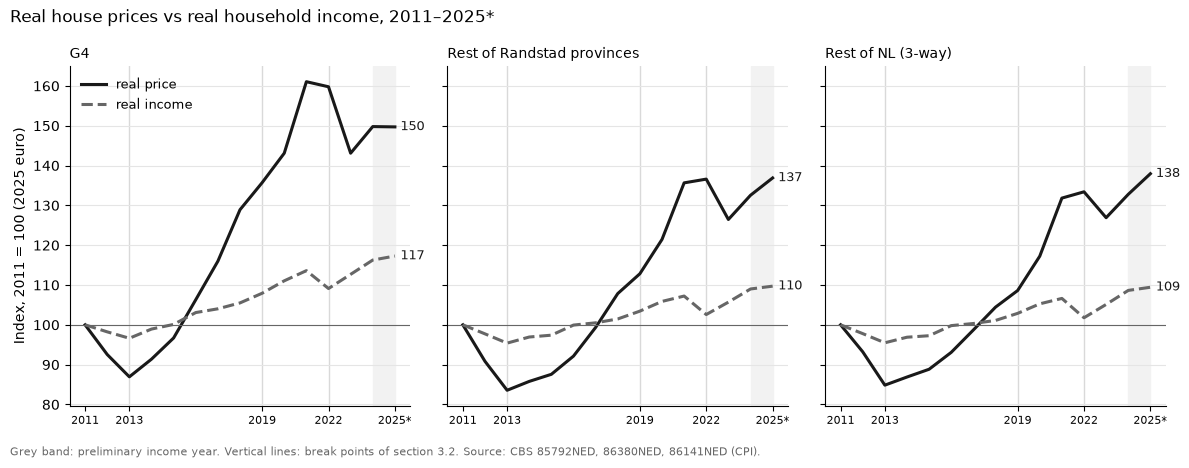

In [27]:
PANEL_GROUPS = [GROUPS[1], GROUPS[2], GROUPS[3]]  # G4, Rest of Randstad provinces, Rest of NL (3-way)
# Price and income are not groups, so they get neutral inks (solid vs dashed), not the group colours.
LINE_STYLE = {"real price": dict(color="#191919", lw=2.2), "real income": dict(color="#666666", lw=2.2, ls="--")}

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), sharey=True)
for ax, (gt, gc, name) in zip(axes, PANEL_GROUPS, strict=True):
    g = group_series(gt, gc)
    for col, label in [
        ("real_avg_sale_price_eur_2025", "real price"),
        ("real_median_disposable_income_eur_2025", "real income"),
    ]:
        idx = g[col] / g.loc[BASE_YEAR, col] * 100
        ax.plot(idx.index, idx, **LINE_STYLE[label], label=label)
        ax.annotate(
            f"{idx.loc[LATEST_DATA]:.0f}",
            (LATEST_DATA, idx.loc[LATEST_DATA]),
            xytext=(4, 0),
            textcoords="offset points",
            va="center",
            fontsize=9,
            color="#191919",
        )
    for b in breaks[1:-1]:
        ax.axvline(b, color="#d9d9d9", lw=1, zorder=0)
    ax.axhline(100, color="#666666", lw=0.8)
    ax.axvspan(LATEST_FINAL, LATEST_DATA, color="#f2f2f2", zorder=0)
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_xticks(
        [BASE_YEAR, trough_year, gap_peak_year, nl_peak_year, LATEST_DATA],
        [str(y) for y in [BASE_YEAR, trough_year, gap_peak_year, nl_peak_year]] + [YEAR_LABEL[LATEST_DATA]],
        fontsize=8,
    )
    ax.grid(axis="y", color="#e5e5e5", lw=0.8)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel(f"Index, {BASE_YEAR} = 100 (2025 euro)")
axes[0].legend(frameon=False, loc="upper left", fontsize=9)
fig.suptitle(f"Real house prices vs real household income, {BASE_YEAR}–{YEAR_LABEL[LATEST_DATA]}", x=0.01, ha="left")
fig.text(
    0.01,
    0.01,
    "Grey band: preliminary income year. Vertical lines: break points of section 3.2. "
    "Source: CBS 85792NED, 86380NED, 86141NED (CPI).",
    fontsize=8,
    color="#666666",
)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIG_DIR / "03_real_price_vs_income.png", dpi=150, facecolor="white")
plt.show()

### 3.3 Municipalities: how widespread is the gap?

Price growth > income growth 2011-2024: 97.4% of 342 municipalities


,municipalities,share_price_faster,median_gap_pp
region_group_3,,,
G4,4,1.00,43.73
Rest of Randstad provinces,116,0.95,35.56
Rest of NL,222,0.99,30.62


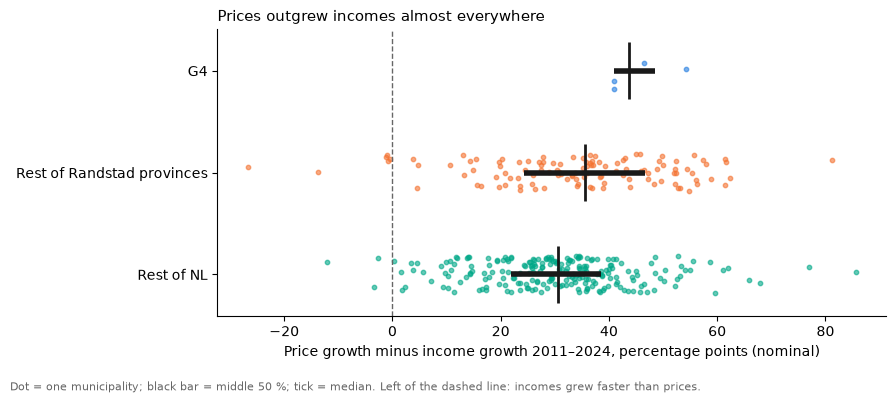

In [28]:
m_final = mun[(mun["year"] == LATEST_FINAL) & mun["growth_gap_pp"].notna()]
share_up = float((m_final["growth_gap_pp"] > 0).mean())
by_group = (
    m_final.groupby("region_group_3")
    .agg(
        municipalities=("growth_gap_pp", "size"),
        share_price_faster=("growth_gap_pp", lambda s: (s > 0).mean()),
        median_gap_pp=("growth_gap_pp", "median"),
    )
    .reindex(["G4", "Rest of Randstad provinces", "Rest of NL"])
)
print(f"Price growth > income growth {BASE_YEAR}-{LATEST_FINAL}: {share_up:.1%} of {len(m_final)} municipalities")
display(by_group)

fig, ax = plt.subplots(figsize=(9, 4))
order = ["Rest of NL", "Rest of Randstad provinces", "G4"]  # bottom to top: G4 on top, as in the tables
data = [m_final.loc[m_final["region_group_3"] == g, "growth_gap_pp"] for g in order]
rng = np.random.default_rng(0)  # fixed seed: the jitter is reproducible
for i, (g, d) in enumerate(zip(order, data, strict=True), start=1):
    ax.scatter(d, i + rng.uniform(-0.18, 0.18, len(d)), s=10, color=GROUP_COLOR[g], alpha=0.6, zorder=2)
    q1, med, q3 = d.quantile([0.25, 0.5, 0.75])
    ax.hlines(i, q1, q3, color="#191919", lw=4, zorder=3)  # interquartile range
    ax.vlines(med, i - 0.28, i + 0.28, color="#191919", lw=2, zorder=3)  # median
ax.set_yticks(range(1, len(order) + 1), order)
ax.axvline(0, color="#666666", lw=1, ls="--")
ax.set_xlabel(f"Price growth minus income growth {BASE_YEAR}–{LATEST_FINAL}, percentage points (nominal)")
ax.set_title("Prices outgrew incomes almost everywhere", loc="left", fontsize=11)
fig.text(
    0.01,
    0.01,
    "Dot = one municipality; black bar = middle 50 %; tick = median. Left of the dashed line: "
    "incomes grew faster than prices.",
    fontsize=8,
    color="#666666",
)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(FIG_DIR / "03_growth_gap_by_municipality.png", dpi=150, facecolor="white")
plt.show()

### 3.4 Robustness checks for section 3

| Check | Why it could change the answer |
|---|---|
| **3A** real instead of nominal | *identity*: every pp gap is the nominal one times CPI(base) / CPI(end); shown, never counted |
| **3B** quality-adjusted price index (85792NED) | the mean price rises when bigger or better homes are sold ("mix"), not only when the same home gets dearer |
| **3C** preliminary year | does the pattern continue in the latest data? |
| **3D** owner-occupier income | the income of the people who actually own homes may have grown differently |

#### 3A. Real vs nominal

In [29]:
display(growth[["gap pp", "real gap pp", "PTI change %"]])
nl_cpi = group_series("nl", "NL01")["cpi_2025_index"]
deflator = nl_cpi[BASE_YEAR] / nl_cpi[LATEST_FINAL]
assert (growth["real gap pp"] - growth["gap pp"] * deflator).abs().max() < 1e-9, "real gap != nominal gap x deflator"
print(
    f"Every real pp gap = nominal pp gap x CPI({BASE_YEAR}) / CPI({LATEST_FINAL}) = x {deflator:.3f}; the ratio "
    "(PTI change %) is identical. Real values change the size of a pp gap, never its sign or ranking."
)

,gap pp,real gap pp,PTI change %
Netherlands,35.84,25.78,23.57
G4,46.60,33.52,28.83
Rest of Randstad provinces,32.72,23.54,21.59
Rest of NL (3-way),33.55,24.13,22.21
Rest of NL (2-way: all but G4),32.88,23.65,21.74


Every real pp gap = nominal pp gap x CPI(2011) / CPI(2024) = x 0.719; the ratio (PTI change %) is identical. Real values change the size of a pp gap, never its sign or ranking.


#### 3B. Mix effect: mean sale price vs the quality-adjusted index

CBS publishes a quality-adjusted price index (85792NED) for NL, the provinces and the four G4 cities, not for other
municipalities. If the mean price grew faster than the index, part of the "price growth" is a shift towards bigger or
better homes being sold. The G4 combined index growth is the base-year-transaction-weighted mean of the four cities.

In [30]:
hpi = q("""
    select region_code, year, price_index_2020, avg_sale_price_eur, transactions_count
    from staging.stg_cbs__house_price_index
""").set_index(["region_code", "year"])
dim_prov = q("select province_code, province_name, is_randstad_province from marts.dim_province")


def index_growth(code_: str, start: int, end: int) -> float:
    return pct(hpi.loc[(code_, end), "price_index_2020"], hpi.loc[(code_, start), "price_index_2020"])


def mean_growth(code_: str, start: int, end: int) -> float:
    return pct(hpi.loc[(code_, end), "avg_sale_price_eur"], hpi.loc[(code_, start), "avg_sale_price_eur"])


regions = [("NL01", "Netherlands", "NL")]
regions += [(c, NAME_OF[c], "G4 city") for c in G4_CODES]
regions += [
    (r.province_code, r.province_name, "Randstad province" if r.is_randstad_province else "other province")
    for r in dim_prov.itertuples()
]
mix = pd.DataFrame(
    [
        {
            "region": name,
            "type": kind,
            "mean price %": mean_growth(c, BASE_YEAR, LATEST_FINAL),
            "quality-adjusted %": index_growth(c, BASE_YEAR, LATEST_FINAL),
        }
        for c, name, kind in regions
    ]
)
mix["mean overstates by pp"] = mix["mean price %"] - mix["quality-adjusted %"]
display(mix.sort_values(["type", "mean overstates by pp"]))
display(mix.groupby("type")["mean overstates by pp"].agg(["min", "median", "max"]))


def g4_index_growth(start: int, end: int) -> float:
    # Quality-adjusted price growth of the four cities combined, weighted by their base-year transactions.
    w = hpi.loc[[(c, start) for c in G4_CODES], "transactions_count"].to_numpy(dtype=float)
    g = np.array([index_growth(c, start, end) for c in G4_CODES])
    return float((w * g).sum() / w.sum())


print(
    f"Quality-adjusted price growth {BASE_YEAR}-{LATEST_FINAL}: G4 combined {g4_index_growth(BASE_YEAR, LATEST_FINAL):.1f} %, "
    f"NL {index_growth('NL01', BASE_YEAR, LATEST_FINAL):.1f} %"
)
print(
    f"Quality-adjusted price growth {nl_peak_year}-{LATEST_FINAL}: G4 combined {g4_index_growth(nl_peak_year, LATEST_FINAL):.1f} %, "
    f"NL {index_growth('NL01', nl_peak_year, LATEST_FINAL):.1f} % "
    f"(mean price: G4 {growth_table(nl_peak_year, LATEST_FINAL, TWO_WAY).loc['G4', 'price %']:.1f} %)"
)

,region,type,mean price %,quality-adjusted %,mean overstates by pp
1,Utrecht,G4 city,103.19,118.17,-14.98
4,Rotterdam,G4 city,107.62,105.11,2.51
2,Amsterdam,G4 city,116.97,113.17,3.80
3,'s-Gravenhage,G4 city,96.76,90.42,6.34
0,Netherlands,NL,87.86,81.90,5.96
11,Utrecht,Randstad province,86.18,88.60,-2.43
12,Noord-Holland,Randstad province,95.26,92.73,2.53
13,Zuid-Holland,Randstad province,90.10,85.62,4.49
5,Groningen,other province,88.19,84.06,4.13
9,Flevoland,other province,112.22,104.77,7.45


,min,median,max
type,,,
G4 city,-14.98,3.16,6.34
NL,5.96,5.96,5.96
Randstad province,-2.43,2.53,4.49
other province,4.13,11.36,13.73


Quality-adjusted price growth 2011-2024: G4 combined 107.1 %, NL 81.9 %
Quality-adjusted price growth 2022-2024: G4 combined 4.0 %, NL 5.6 % (mean price: G4 0.6 %)


#### 3C. Preliminary year and 3D. Owner-occupier income

In [31]:
growth_prelim = growth_table(BASE_YEAR, LATEST_DATA)
display(Markdown(f"**Growth {BASE_YEAR} → {YEAR_LABEL[LATEST_DATA]}**"))
display(growth_prelim[["price %", "income %", "gap pp", "real gap pp"]])

owner_growth = pd.DataFrame(
    {
        "price %": growth["price %"],
        "owner income %": (owner_income.loc[LATEST_FINAL] / owner_income.loc[BASE_YEAR] - 1) * 100,
    }
)
owner_growth["gap pp (owner)"] = owner_growth["price %"] - owner_growth["owner income %"]
display(Markdown(f"**Price growth vs owner-occupier income growth, {BASE_YEAR} → {LATEST_FINAL}**"))
display(owner_growth)

owner_inc = mun.pivot(index="municipality_code", columns="year", values="median_disposable_income_owner_eur")
price_m = mun.pivot(index="municipality_code", columns="year", values="avg_sale_price_eur")
real_p = mun.pivot(index="municipality_code", columns="year", values="real_avg_sale_price_eur_2025")
real_i = mun.pivot(index="municipality_code", columns="year", values="real_median_disposable_income_eur_2025")
inc_m = mun.pivot(index="municipality_code", columns="year", values="median_disposable_income_eur")


def share_price_faster(p: pd.DataFrame, i: pd.DataFrame, end: int) -> float:
    # Share of municipalities whose price grew faster than income between the base year and `end`.
    ok = (p[end] / p[BASE_YEAR] > i[end] / i[BASE_YEAR]).where(p[end].notna() & i[end].notna())
    return float(ok.dropna().mean())


share_real = share_price_faster(real_p, real_i, LATEST_FINAL)
share_prelim = share_price_faster(price_m, inc_m, LATEST_DATA)
share_owner = share_price_faster(price_m, owner_inc, LATEST_FINAL)
assert abs(share_price_faster(price_m, inc_m, LATEST_FINAL) - share_up) < 1e-12
print(
    f"Share of municipalities with price growth > income growth: nominal {share_up:.1%}, real {share_real:.1%}, "
    f"{YEAR_LABEL[LATEST_DATA]} {share_prelim:.1%}, owner-occupier income {share_owner:.1%}"
)

**Growth 2011 → 2025***

,price %,income %,gap pp,real gap pp
Netherlands,99.75,57.94,41.81,29.14
G4,114.78,68.26,46.53,32.43
Rest of Randstad provinces,96.39,57.40,38.99,27.18
Rest of NL (3-way),97.92,57.00,40.92,28.52
Rest of NL (2-way: all but G4),96.89,57.18,39.71,27.68


**Price growth vs owner-occupier income growth, 2011 → 2024**

,price %,owner income %,gap pp (owner)
Netherlands,87.86,59.38,28.49
G4,108.24,69.56,38.68
Rest of Randstad provinces,84.26,57.39,26.87
Rest of NL (3-way),84.58,58.61,25.97
Rest of NL (2-way: all but G4),84.12,58.22,25.90


Share of municipalities with price growth > income growth: nominal 97.4%, real 97.4%, 2025* 98.5%, owner-occupier income 93.9%


In [32]:
def lead(t: pd.DataFrame, col: str = "gap pp") -> float:
    # G4 minus Rest of NL (2-way) for a column of a growth table.
    return t.loc["G4", col] - t.loc[REST2, col]


CLAIM_3A = "Prices outran incomes more in the G4 (G4 gap minus Rest-of-NL gap, pp)"
base_lead = lead(growth)
record("F3", CLAIM_3A, "3A real terms", base_lead, lead(growth, "real gap pp"), kind="identity")
g4_q = g4_index_growth(BASE_YEAR, LATEST_FINAL) - growth.loc["G4", "income %"]
nl_q = index_growth("NL01", BASE_YEAR, LATEST_FINAL) - growth.loc["Netherlands", "income %"]
record("F3", CLAIM_3A, "3B quality-adjusted (vs NL)", base_lead, g4_q - nl_q)
record("F3", CLAIM_3A, "3C preliminary year", base_lead, lead(growth_prelim))
record(
    "F3",
    CLAIM_3A,
    "3D owner-occupier income",
    base_lead,
    owner_growth.loc["G4", "gap pp (owner)"] - owner_growth.loc[REST2, "gap pp (owner)"],
)

after_peak = growth_table(nl_peak_year, LATEST_FINAL, TWO_WAY)
CLAIM_3B = f"After the {nl_peak_year} peak, G4 prices lagged the rest (G4 minus Rest of NL price growth, pp)"
base_lag = lead(after_peak, "price %")
record("F3", CLAIM_3B, "3A real terms", base_lag, lead(after_peak, "real price %"), kind="identity")
record(
    "F3",
    CLAIM_3B,
    "3B quality-adjusted (vs NL)",
    base_lag,
    g4_index_growth(nl_peak_year, LATEST_FINAL) - index_growth("NL01", nl_peak_year, LATEST_FINAL),
)
record(
    "F3", CLAIM_3B, "3C preliminary year", base_lag, lead(growth_table(nl_peak_year, LATEST_DATA, TWO_WAY), "price %")
)

CLAIM_3C = "Prices outgrew incomes in almost every municipality (share; holds if >= 90 %)"
for check, x in [
    ("3A real terms", share_real),
    ("3C preliminary year", share_prelim),
    ("3D owner-occupier income", share_owner),
]:
    record(
        "F3",
        CLAIM_3C,
        check,
        share_up,
        x,
        fmt="{:.0%}",
        kind="identity" if check.startswith("3A") else "threshold",
        thresholds={"lenient": (0.8, 0.5), "default": (0.9, 0.5), "strict": (0.95, 0.75)},
    )

display(register("F3").drop(columns="finding"))

,claim,check,type,baseline,variant,verdict
0,Prices outran incomes more in the G4 (G4 gap m...,3A real terms,identity,+13.73,+9.87,identical
1,Prices outran incomes more in the G4 (G4 gap m...,3B quality-adjusted (vs NL),alternative specification,+13.73,+15.54,holds
2,Prices outran incomes more in the G4 (G4 gap m...,3C preliminary year,data vintage,+13.73,+6.82,weaker
3,Prices outran incomes more in the G4 (G4 gap m...,3D owner-occupier income,alternative specification,+13.73,+12.78,holds
4,"After the 2022 peak, G4 prices lagged the rest...",3A real terms,identity,-5.14,-4.79,identical
5,"After the 2022 peak, G4 prices lagged the rest...",3B quality-adjusted (vs NL),alternative specification,-5.14,-1.60,weaker
6,"After the 2022 peak, G4 prices lagged the rest...",3C preliminary year,data vintage,-5.14,-9.31,holds
7,Prices outgrew incomes in almost every municip...,3A real terms,identity,97%,97%,identical
8,Prices outgrew incomes in almost every municip...,3C preliminary year,data vintage,97%,99%,holds
9,Prices outgrew incomes in almost every municip...,3D owner-occupier income,alternative specification,97%,94%,holds


### Finding 3

In [33]:
p1 = sub.loc[f"{trough_year}-{gap_peak_year}"]
p2 = sub.loc[f"{gap_peak_year}-{nl_peak_year}"]
p3 = sub.loc[f"{nl_peak_year}-{LATEST_FINAL}"]
lead_vs_nl = growth.loc["G4", "gap pp"] - growth.loc["Netherlands", "gap pp"]  # same comparator as the index check
lead_owner = owner_growth.loc["G4", "gap pp (owner)"] - owner_growth.loc[REST2, "gap pp (owner)"]
lead_prelim = lead(growth_prelim)
mix_other = mix.loc[mix["type"] == "other province", "mean overstates by pp"]
mix_g4 = mix.loc[mix["type"] == "G4 city", "mean overstates by pp"]
nl_mix = mix.loc[mix["type"] == "NL", "mean overstates by pp"].item()
g4_q_after = g4_index_growth(nl_peak_year, LATEST_FINAL)
nl_q_after = index_growth("NL01", nl_peak_year, LATEST_FINAL)

assert share_up >= 0.9, "'almost every municipality'"
assert base_lead > 0 and growth["gap pp"].idxmax() == "G4", "'the gap was widest in the G4'"
assert p1["G4 minus rest, price pp"] > 0, "'G4 prices raced ahead'"
assert p2["G4 minus rest, price pp"] < 0, "'the rest of the country caught up'"
assert p3["G4 price %"] < p3["G4 income %"] and p3["G4 minus rest, price pp"] < 0, "'G4 prices stalled'"
g4_real_after = after_peak.loc["G4", "real price %"]
assert p3["G4 price %"] >= 0 > g4_real_after, "'nominal prices standing still, a real fall'"
assert lead_owner > 0 and g4_q - nl_q > 0, "'the G4 lead remains with owner income and on the index'"
assert g4_q - nl_q > lead_vs_nl, "'like for like the G4 lead is, if anything, larger'"
assert 0 < lead_prelim < base_lead, "'it shrinks when the preliminary year is the end point'"
assert mix_other.min() > mix_g4.median(), "'the mix effect is larger outside the G4'"
assert base_lag < g4_q_after - nl_q_after < 0, (
    "'the post-peak lag is smaller, but still there, on the quality-adjusted index'"
)

display(
    Markdown(f"""
**Finding 3. Prices outgrew incomes almost everywhere, most of all in the G4, which pulled ahead in the boom years and
has been losing ground since.**

From {BASE_YEAR} to {LATEST_FINAL} house prices grew faster than household incomes in {share_up * 100:.0f} % of municipalities.
The gap was widest in the G4: prices +{growth.loc["G4", "price %"]:.0f} % against incomes +{growth.loc["G4", "income %"]:.0f} %
(rest of NL: +{growth.loc[REST2, "price %"]:.0f} % vs +{growth.loc[REST2, "income %"]:.0f} %). After inflation, G4 prices
rose {growth.loc["G4", "real price %"]:.0f} % in real terms and incomes {growth.loc["G4", "real income %"]:.0f} %;
in the rest of NL real incomes grew only {growth.loc[REST2, "real income %"]:.0f} % in {LATEST_FINAL - BASE_YEAR} years.
The timing explains finding 1: in {trough_year}–{gap_peak_year} G4 prices rose {p1["G4 price %"]:.0f} % against
{p1["Rest of NL price %"]:.0f} % elsewhere; in {gap_peak_year}–{nl_peak_year} the rest of the country caught up
({p2["Rest of NL price %"]:.0f} % vs {p2["G4 price %"]:.0f} %); after {nl_peak_year} G4 mean prices stalled
(+{p3["G4 price %"]:.1f} %) while G4 incomes rose {p3["G4 income %"]:.0f} %.

**Robustness.** The G4 lead remains with owner-occupier income ({lead_owner:+.1f} pp) and on the quality-adjusted
index. Mean prices overstate like-for-like growth by {nl_mix:.0f} pp nationally and by
{mix_other.min():.0f}–{mix_other.max():.0f} pp in provinces outside the Randstad, but by a median of only
{mix_g4.median():.0f} pp in the four cities, so like for like the G4 lead over NL is, if anything, larger
({g4_q - nl_q:+.1f} pp against {lead_vs_nl:+.1f} pp with mean prices). It shrinks from {base_lead:.1f} to {lead_prelim:.1f} pp when the
preliminary year {YEAR_LABEL[LATEST_DATA]} is the end point: the catch-up of the rest of the country continues. The
post-{nl_peak_year} stall is partly a mix effect: quality-adjusted G4 prices rose {g4_q_after:.1f} % against
{nl_q_after:.1f} % nationally, a smaller lag than the mean prices suggest.

**So what.** The affordability squeeze is not only a big-city story: in most of the country incomes kept up with
inflation only barely while prices raced ahead. The G4's relative improvement since {nl_peak_year} came from nominal prices
standing still (a real fall of {-g4_real_after:.0f} %) while incomes rose, not from homes getting cheaper in euros.
""")
)


**Finding 3. Prices outgrew incomes almost everywhere, most of all in the G4, which pulled ahead in the boom years and
has been losing ground since.**

From 2011 to 2024 house prices grew faster than household incomes in 97 % of municipalities.
The gap was widest in the G4: prices +108 % against incomes +62 %
(rest of NL: +84 % vs +51 %). After inflation, G4 prices
rose 50 % in real terms and incomes 16 %;
in the rest of NL real incomes grew only 9 % in 13 years.
The timing explains finding 1: in 2013–2019 G4 prices rose 68 % against
41 % elsewhere; in 2019–2022 the rest of the country caught up
(40 % vs 35 %); after 2022 G4 mean prices stalled
(+0.6 %) while G4 incomes rose 14 %.

**Robustness.** The G4 lead remains with owner-occupier income (+12.8 pp) and on the quality-adjusted
index. Mean prices overstate like-for-like growth by 6 pp nationally and by
4–14 pp in provinces outside the Randstad, but by a median of only
3 pp in the four cities, so like for like the G4 lead over NL is, if anything, larger
(+15.5 pp against +10.8 pp with mean prices). It shrinks from 13.7 to 6.8 pp when the
preliminary year 2025* is the end point: the catch-up of the rest of the country continues. The
post-2022 stall is partly a mix effect: quality-adjusted G4 prices rose 4.0 % against
5.6 % nationally, a smaller lag than the mean prices suggest.

**So what.** The affordability squeeze is not only a big-city story: in most of the country incomes kept up with
inflation only barely while prices raced ahead. The G4's relative improvement since 2022 came from nominal prices
standing still (a real fall of 6 %) while incomes rose, not from homes getting cheaper in euros.


---
## 4. Robustness matrix

Every claim of findings 1–3 under every check that applies to it. Each check has a **type**:

| Type | What it tests | Counted as evidence? |
|---|---|---|
| alternative specification | a different, defensible definition of the same quantity: owner-occupier income, median of municipal PTIs, quality-adjusted prices, small municipalities included | yes |
| data vintage | the same specification on the preliminary latest year, which CBS will revise | yes |
| data-quality control | the same specification without rows that are reconstructed (harmonised municipalities) | yes |
| identity | a re-expression that is mathematically bound to agree (real vs nominal: one CPI factor) | **no** — shown only to document that it was considered |

The checks are **not independent confirmations**: all reuse the same CBS sales and income data, and one check
(e.g. owner-occupier income) is applied to several claims. The counts describe how many re-measurements were made.

In [34]:
VERDICT_BG = {"holds": "#e3f4e6", "weaker": "#fff1cc", "reverses": "#fbe0e0", "identical": "#eeeeee"}
styled = (
    register()
    .set_index(["finding", "claim", "check"])
    .style.map(lambda v: f"background-color: {VERDICT_BG.get(v, '')}; color: #191919", subset=["verdict"])
    .set_uuid("robustness")  # fixed id: re-running on the same data gives an identical notebook
)
display(HTML(styled.to_html()))

In [35]:
rob = pd.DataFrame(ROBUSTNESS)
evidence = rob[rob["check_type"].isin(EVIDENCE_TYPES)]
identities = rob[~rob["check_type"].isin(EVIDENCE_TYPES)]


def verdict_counts(verdicts: pd.Series) -> dict:
    return {v: int((verdicts == v).sum()) for v in ["holds", "weaker", "reverses"]}


by_type = pd.DataFrame(
    {t: verdict_counts(evidence.loc[evidence["check_type"] == t, "verdict"]) for t in EVIDENCE_TYPES}
).T
by_type["checks"] = by_type.sum(axis=1)
by_type.loc["identity (not counted)"] = [0, 0, 0, len(identities)]
display(by_type)

COUNTS = verdict_counts(evidence["verdict"])
N_EVIDENCE, N_IDENTITY = len(evidence), len(identities)
print(
    f"{N_EVIDENCE} evidence checks: {COUNTS['holds']} hold, {COUNTS['weaker']} weaker, {COUNTS['reverses']} reverse; "
    f"{N_IDENTITY} identities shown but not counted."
)

,holds,weaker,reverses,checks
alternative specification,13,2,1,16
data vintage,7,2,0,9
data-quality control,1,0,0,1
identity (not counted),0,0,0,6


26 evidence checks: 21 hold, 4 weaker, 1 reverse; 6 identities shown but not counted.


### 4.1 Does the verdict rule drive the labels?

The default rule ("holds" = same direction and at least **half** the baseline size; stated levels for shares, rank
correlations and counts) is an editorial heuristic written down in D-036, not a statistical test: the data are the
full population of municipalities, so there is no sampling error to test against. To show how much the labels depend
on it, every evidence check is re-labelled under a **lenient** (¼ of the size; lower levels) and a **strict** (¾;
higher levels) rule.

The finding texts in sections 1–3 do not use these labels: they state the baseline and the variant value
("shrinks from 13.7 to 6.8 pp"), and their `assert`s test magnitudes. So the rule changes the colour of a cell in
the matrix, never a sentence of a finding.

In [36]:
relabelled = pd.DataFrame({rule: [verdict(r, rule) for r in ROBUSTNESS] for rule in RULE_SETS})
relabelled[["finding", "claim", "check"]] = rob[["finding", "claim", "check"]]
relabelled = relabelled[rob["check_type"].isin(EVIDENCE_TYPES).to_numpy()]

RULE_COUNTS = {rule: verdict_counts(relabelled[rule]) for rule in RULE_SETS}
display(pd.DataFrame(RULE_COUNTS).T.rename_axis("rule"))

changed = relabelled[(relabelled["lenient"] != relabelled["default"]) | (relabelled["strict"] != relabelled["default"])]
display(Markdown(f"**Labels that depend on the rule** ({len(changed)} of {len(relabelled)})"))
display(changed.set_index(["finding", "claim", "check"])[RULE_SETS])

,holds,weaker,reverses
rule,,,
lenient,25,1,0
default,21,4,1
strict,17,8,1


**Labels that depend on the rule** (9 of 26)

lenient   default    strict
finding claim                                              check                                                  
F1      NL PTI rose since the base year (PTI points)       1B owner-occupier income      holds     holds    weaker
        G4 / Rest of NL ratio widened since the base year  1A preliminary year           holds    weaker    weaker
                                                           1C typical municipality       holds     holds    weaker
        G4 PTI is well above the rest (G4 / Rest of NL ... 1B owner-occupier income      holds    weaker    weaker
                                                           1C typical municipality       holds     holds    weaker
F2      G4 cities are in the least-affordable third (co... 2A owner-occupier PTI        weaker  reverses  reverses
F3      Prices outran incomes more in the G4 (G4 gap mi... 3C preliminary year           holds    weaker    weaker
        After the 2022 peak, G4 prices lagged the rest ... 3B quality-adjusted (vs NL)   holds    weaker    weaker
        Prices outgrew incomes in almost every municipa... 3D owner-occupier income      holds     holds    weaker

In [37]:
weak = register()[lambda d: d["verdict"].isin(["weaker", "reverses"])]
lines = [
    f"- **{r.finding}**: *{r.claim}* is **{r.verdict}** under **{r.check}** ({r.variant} vs {r.baseline})"
    for r in weak.itertuples()
]
display(Markdown("**Claims that do not fully survive a check (default rule)**\n\n" + "\n".join(lines)))

**Claims that do not fully survive a check (default rule)**

- **F1**: *G4 / Rest of NL ratio widened since the base year* is **weaker** under **1A preliminary year** (+0.03 vs +0.08)
- **F1**: *G4 PTI is well above the rest (G4 / Rest of NL - 1)* is **weaker** under **1B owner-occupier income** (+0.11 vs +0.39)
- **F2**: *G4 cities are in the least-affordable third (count of 4; holds if >= 3)* is **reverses** under **2A owner-occupier PTI** (1 vs 4)
- **F3**: *Prices outran incomes more in the G4 (G4 gap minus Rest-of-NL gap, pp)* is **weaker** under **3C preliminary year** (+6.82 vs +13.73)
- **F3**: *After the 2022 peak, G4 prices lagged the rest (G4 minus Rest of NL price growth, pp)* is **weaker** under **3B quality-adjusted (vs NL)** (-1.60 vs -5.14)

### 4.2 Headline numbers by income basis

The all-household PTI compares prices with what **residents** earn (renters included), not with what **buyers**
earn. Owner-occupier income is the closest proxy for buyers in the data. Where few households own their home the two
bases differ most, so the headline numbers are shown side by side; the README and the dashboard show both (D-038).

In [38]:
latest = fct[fct["year"] == LATEST_FINAL].merge(dim_mun[["municipality_code", "region_group"]], on="municipality_code")
owner_latest = own[own["year"] == LATEST_FINAL]
owner_share = (
    owner_latest.groupby("region_group")["owner_households"].sum()
    / latest.groupby("region_group")["households_count"].sum()
)
OWNER_SHARE_G4, OWNER_SHARE_REST = float(owner_share["G4"]), float(owner_share["Rest of NL"])
print(
    f"Owner-occupier share of households, {LATEST_FINAL}: G4 {OWNER_SHARE_G4 * 100:.0f} %, rest of NL {OWNER_SHARE_REST * 100:.0f} %"
)

BY_INCOME = pd.DataFrame(
    {
        "all households": [
            f"{gap_all[BASE_YEAR]:.2f}×",
            f"{gap_all[LATEST_FINAL]:.2f}×",
            f"{nl_rise:+.2f}",
            f"{base_g4} of 4",
            f"{share_up * 100:.0f} %",
        ],
        "owner-occupiers": [
            f"{gap_owner[BASE_YEAR]:.2f}×",
            f"{gap_owner[LATEST_FINAL]:.2f}×",
            f"{pti_owner.loc[LATEST_FINAL, 'Netherlands'] - pti_owner.loc[BASE_YEAR, 'Netherlands']:+.2f}",
            f"{g4_in_top_third(r_owner)} of 4",
            f"{share_owner * 100:.0f} %",
        ],
    },
    index=[
        f"G4 PTI ÷ rest-of-NL PTI, {BASE_YEAR}",
        f"G4 PTI ÷ rest-of-NL PTI, {LATEST_FINAL}",
        f"NL PTI change {BASE_YEAR}–{LATEST_FINAL} (points)",
        f"G4 cities in the least-affordable third, {LATEST_FINAL}",
        f"Municipalities where prices outgrew incomes, {BASE_YEAR}–{LATEST_FINAL}",
    ],
)
display(BY_INCOME)

Owner-occupier share of households, 2024: G4 36 %, rest of NL 62 %


,all households,owner-occupiers
"G4 PTI ÷ rest-of-NL PTI, 2011",1.31×,1.05×
"G4 PTI ÷ rest-of-NL PTI, 2024",1.39×,1.11×
NL PTI change 2011–2024 (points),+1.76,+1.03
"G4 cities in the least-affordable third, 2024",4 of 4,1 of 4
"Municipalities where prices outgrew incomes, 2011–2024",97 %,94 %


---
## 5. What the PTI does not tell you

Plain-language limitations of this analysis, with the size of each one where the data can measure it.

In [39]:
n_small = int(dim_year.set_index("year").loc[LATEST_FINAL, "municipalities_with_pti"] - len(r_final))
display(
    Markdown(f"""
1. **It is not "years of income needed to buy a home".** The ratio divides a *mean* price by a *median* income
   (CBS publishes no median price per municipality), so its level is higher than a like-for-like ratio would be.
   This notebook therefore compares changes and rankings, not levels (D-004).
2. **The mean price follows the mix of homes sold.** When more large or new homes are sold, the mean rises even if no
   home got dearer. Nationally this mix effect added {nl_mix:.0f} percentage points to price growth
   {BASE_YEAR}–{LATEST_FINAL} (section 3B). A quality-adjusted index exists only for NL, provinces and the G4.
3. **It ignores the cost of borrowing.** The same PTI means a much higher monthly payment when mortgage rates are high.
   The {nl_peak_year} PTI peak and the fall afterwards coincide with rising mortgage rates, but this notebook has no rate
   data to test that link; the rate scenarios belong to business question 4 (D-013).
4. **It is about buyers' income, measured as everyone's income.** The median covers renters and owners alike. Where
   many renters and one-person households live, the ratio looks worse than it is for typical buyers: with owner-occupier
   income the G4's lead over the rest of NL shrinks from {gap_all[LATEST_FINAL]:.2f}× to {gap_owner[LATEST_FINAL]:.2f}×
   (section 1B). The true buyer (first-time buyer, cross-border buyer, investor) is not in the data.
5. **It ignores wealth and equity.** Existing owners who move use the value of their current home; first-time buyers do
   not. Two municipalities with the same PTI can be very different places for a first-time buyer.
6. **Small municipalities are noisy.** {n_small} municipalities with fewer than 5 000 households have a PTI but no rank in
   {LATEST_FINAL}; a few sales can move their average a lot (section 2B).
7. **The latest year is preliminary.** {YEAR_LABEL[LATEST_DATA]} incomes will be revised; every headline uses
   {LATEST_FINAL}, and the preliminary year is a check (1A, 2C, 3C).
8. **Borders and groups are reconstructed.** All years use the municipalities of 2026; prices of merged municipalities
   are weighted averages of their predecessors (D-007), group incomes are approximations validated within 2 % of the
   official NL median (D-016), and the G4 price excludes Weesp before it joined Amsterdam in 2022 (D-029).
9. **It describes, it does not explain.** The analysis shows *where* and *when* affordability changed. It does not
   show *why* (supply, rates, demand from investors or migration); those need other data and methods.
""")
)


1. **It is not "years of income needed to buy a home".** The ratio divides a *mean* price by a *median* income
   (CBS publishes no median price per municipality), so its level is higher than a like-for-like ratio would be.
   This notebook therefore compares changes and rankings, not levels (D-004).
2. **The mean price follows the mix of homes sold.** When more large or new homes are sold, the mean rises even if no
   home got dearer. Nationally this mix effect added 6 percentage points to price growth
   2011–2024 (section 3B). A quality-adjusted index exists only for NL, provinces and the G4.
3. **It ignores the cost of borrowing.** The same PTI means a much higher monthly payment when mortgage rates are high.
   The 2022 PTI peak and the fall afterwards coincide with rising mortgage rates, but this notebook has no rate
   data to test that link; the rate scenarios belong to business question 4 (D-013).
4. **It is about buyers' income, measured as everyone's income.** The median covers renters and owners alike. Where
   many renters and one-person households live, the ratio looks worse than it is for typical buyers: with owner-occupier
   income the G4's lead over the rest of NL shrinks from 1.39× to 1.11×
   (section 1B). The true buyer (first-time buyer, cross-border buyer, investor) is not in the data.
5. **It ignores wealth and equity.** Existing owners who move use the value of their current home; first-time buyers do
   not. Two municipalities with the same PTI can be very different places for a first-time buyer.
6. **Small municipalities are noisy.** 19 municipalities with fewer than 5 000 households have a PTI but no rank in
   2024; a few sales can move their average a lot (section 2B).
7. **The latest year is preliminary.** 2025* incomes will be revised; every headline uses
   2024, and the preliminary year is a check (1A, 2C, 3C).
8. **Borders and groups are reconstructed.** All years use the municipalities of 2026; prices of merged municipalities
   are weighted averages of their predecessors (D-007), group incomes are approximations validated within 2 % of the
   official NL median (D-016), and the G4 price excludes Weesp before it joined Amsterdam in 2022 (D-029).
9. **It describes, it does not explain.** The analysis shows *where* and *when* affordability changed. It does not
   show *why* (supply, rates, demand from investors or migration); those need other data and methods.


---
## 6. Export: key findings for the README

The README section *Key insights* is not typed by hand. This cell renders it from the numbers above (every claim
word is guarded by an `assert` in sections 1–3) and writes it to `docs/KEY_FINDINGS.md` and between the markers in
`README.md` (`nl_housing.report`, D-033). `tests/test_report.py` fails if the two differ; the CI `pipeline` job
re-runs this notebook on fresh CBS data and fails if either file changes, so a CBS revision cannot leave a stale
number in the README.

In [40]:
from nl_housing import report


def md_table(df: pd.DataFrame, index_name: str) -> str:
    # A small DataFrame of strings as a GitHub Markdown table (no extra dependency).
    lines = ["| " + " | ".join([index_name, *df.columns]) + " |", "|---|" + "---:|" * len(df.columns)]
    lines += ["| " + " | ".join([str(i), *row]) + " |" for i, row in zip(df.index, df.to_numpy(), strict=True)]
    return "\n".join(lines)


TABLE_GROUPS = ["Netherlands", "G4", "Rest of Randstad provinces", "Rest of NL (3-way)"]
group_table = pd.DataFrame(
    {
        f"PTI {BASE_YEAR}": [f"{v:.2f}" for v in pti.loc[BASE_YEAR, TABLE_GROUPS]],
        f"PTI {LATEST_FINAL}": [f"{v:.2f}" for v in pti.loc[LATEST_FINAL, TABLE_GROUPS]],
        f"PTI {YEAR_LABEL[LATEST_DATA]}": [f"{v:.2f}" for v in pti.loc[LATEST_DATA, TABLE_GROUPS]],
        f"Price growth minus income growth {BASE_YEAR}–{LATEST_FINAL} (pp)": [
            f"{v:.1f}" for v in growth.loc[TABLE_GROUPS, "gap pp"]
        ],
    },
    index=["Netherlands", "G4", "Rest of Randstad provinces", "Rest of NL"],
)

KEY_FINDINGS = f"""_Generated by `notebooks/01_affordability_findings.ipynb` (section 6); do not edit by hand. Base year {BASE_YEAR},
headline year {LATEST_FINAL} (final income), {YEAR_LABEL[LATEST_DATA]} = preliminary income._

**How to read the PTI.** PTI = average sale price of existing homes ÷ median disposable income of **all** households
in the municipality, renters included. It compares prices with what *residents* earn, not with what *buyers* earn,
and it mixes a mean with a median, so it is a relative index, not "years of income needed to buy". The two differ
most where few households own their home ({OWNER_SHARE_G4 * 100:.0f} % of households in the G4 against
{OWNER_SHARE_REST * 100:.0f} % elsewhere), so every finding is also shown with owner-occupier income.

1. **Homes became less affordable everywhere, most of all in the G4, but the G4's lead peaked in {gap_peak_year}.**
   The national PTI rose from {pti.loc[BASE_YEAR, "Netherlands"]:.1f} ({BASE_YEAR}) to
   {pti.loc[LATEST_FINAL, "Netherlands"]:.1f} ({LATEST_FINAL}), +{change_pct["Netherlands"]:.0f} %, after a peak of
   {pti.loc[nl_peak_year, "Netherlands"]:.1f} in {nl_peak_year}. The G4 rose most ({pti.loc[BASE_YEAR, "G4"]:.1f} →
   {pti.loc[LATEST_FINAL, "G4"]:.1f}, +{change_pct["G4"]:.0f} %); relative to the rest of NL it went from
   {gap_all[BASE_YEAR]:.2f}× to {gap_all[LATEST_FINAL]:.2f}×, below its {gap_peak_year} peak of
   {gap_all[gap_peak_year]:.2f}×. With owner-occupier income the G4's lead is {gap_owner[LATEST_FINAL]:.2f}×: most of the
   gap reflects *who lives* in the cities (many renters and one-person households), not only what homes cost.
2. **The least affordable places are wealthy suburbs, not the G4, and the map hardly changes.**
   {k_suburbs} of the {TOP_N} least affordable municipalities in {LATEST_FINAL} lie in the Randstad provinces outside the
   G4 (top 3: {", ".join(NAME_OF[top3])}); Amsterdam (rank {r_final[g4_in_top10[0]]}) is the only G4 city in the top 10.
   The {BASE_YEAR} and {LATEST_FINAL} rankings correlate at {rho:.2f}. Ranked by owner-occupier income,
   {WORDS[4 - owner_g4_third]} of the four G4 cities leave the least-affordable third (Rotterdam: rank {r_final[rot]} →
   {r_owner[rot]}).
3. **Prices outgrew incomes in {share_up * 100:.0f} % of municipalities.** In the G4 prices rose
   {growth.loc["G4", "price %"]:.0f} % against incomes {growth.loc["G4", "income %"]:.0f} % (after inflation:
   +{growth.loc["G4", "real price %"]:.0f} % vs +{growth.loc["G4", "real income %"]:.0f} %); in the rest of NL
   +{growth.loc[REST2, "price %"]:.0f} % vs +{growth.loc[REST2, "income %"]:.0f} %, with real incomes up only
   {growth.loc[REST2, "real income %"]:.0f} % in {LATEST_FINAL - BASE_YEAR} years. The G4 pulled ahead in
   {trough_year}–{gap_peak_year} (+{p1["G4 price %"]:.0f} % vs +{p1["Rest of NL price %"]:.0f} %), the rest caught up in
   {gap_peak_year}–{nl_peak_year}, and after {nl_peak_year} G4 prices stood still in euros (+{p3["G4 price %"]:.1f} %,
   a real fall of {-g4_real_after:.0f} %) while incomes rose {p3["G4 income %"]:.0f} %.

**Robustness.** {N_EVIDENCE} re-measurements under alternative specifications, the preliminary year and a
data-quality control: {COUNTS["holds"]} hold, {COUNTS["weaker"]} weaker, {COUNTS["reverses"]} reverse with the default
rule (lenient rule: {RULE_COUNTS["lenient"]["holds"]} / {RULE_COUNTS["lenient"]["weaker"]} /
{RULE_COUNTS["lenient"]["reverses"]}; strict rule: {RULE_COUNTS["strict"]["holds"]} / {RULE_COUNTS["strict"]["weaker"]} /
{RULE_COUNTS["strict"]["reverses"]}). {N_IDENTITY} real-vs-nominal identities are shown in the notebook but not
counted. The checks reuse the same CBS data, so they are not independent confirmations; every *weaker* and *reverses*
result is named in the notebook's finding texts.

{md_table(BY_INCOME, "Headline by income basis")}

{md_table(group_table, "Group")}
"""
report.write_key_findings(KEY_FINDINGS)  # `git diff` shows whether a re-run changed anything
print(f"Key findings written to docs/KEY_FINDINGS.md and the README block ({len(KEY_FINDINGS.splitlines())} lines)")

Key findings written to docs/KEY_FINDINGS.md and the README block (54 lines)


In [41]:
con.close()  # release the DuckDB file, so `make build` can rewrite it while this kernel is still open